# Diagnóstico de marca empleadora — Nokia vs. Big Tech
## Sentiment analysis (transformers) + topic modeling (BERTopic) sobre reseñas de Glassdoor

**Encargo de RRHH:** Identificar los puntos fuertes y las áreas de mejora de Nokia como empleador, a partir de lo que dicen sus empleados en Glassdoor, y compararlos con los de sus competidores directos en el sector tecnológico.

**Peers elegidos:** Google, Apple, Microsoft y Uber. Son gigantes tecnológicos globales que compiten directa o indirectamente por el mismo perfil de talento (ingeniería de software, telecomunicaciones, data y operaciones).

| Sección | Contenido |
|---|---|
| 0 | Carga y preparación |
| 1 | EDA: rating, recomendación, empleados actuales vs. antiguos |
| 2 | Sentimiento en pros y cons (control de calidad) |
| 3 | Topic modeling con BERTopic y etiquetado de negocio |
| 4 | Comparación con peers y cálculo del Balance Neto |
| 5 | Empleados actuales vs. antiguos |
| 6 | Conclusiones y recomendaciones para RRHH |

In [1]:
# Instalación de librerías requeridas si fuera necesario
# !pip install -q bertopic sentence-transformers transformers nltk torch hdbscan umap-learn scikit-learn pandas matplotlib seaborn pyarrow

---
## 0. Carga y Preparación

In [2]:
# Carga e Importaciones
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.gridspec import GridSpec

# NLP y Deep Learning
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer
import torch
from transformers import pipeline

# Topic Modeling
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer
from sentence_transformers import SentenceTransformer
from bertopic import BERTopic

warnings.filterwarnings('ignore')

# Definición de la empresa objetivo y grupo de comparables
TARGET = 'Nokia'
PEERS = ['Google', 'Apple', 'Microsoft', 'Uber']
FIRMS = [TARGET] + PEERS

MAX_POR_EMPRESA = 2000
SEED = 42

# Carga inicial de las reseñas de Glassdoor desde el archivo parquet
raw = pd.read_parquet('../data/raw/glassdoor_reviews_hr.parquet', filters=[('firm', 'in', FIRMS)])
print('Reseñas disponibles por empresa:')
print(raw['firm'].value_counts())

# Muestreo estratificado para balancear las empresas y fijar la semilla
df = pd.concat([g.sample(n=min(MAX_POR_EMPRESA, len(g)), random_state=SEED)
                for _, g in raw.groupby('firm')], ignore_index=True)
print(f'\nMuestra de trabajo consolidada: {len(df):,} reseñas')

Reseñas disponibles por empresa:
firm
Google       20889
Microsoft    19791
Apple        19208
Uber          8778
Nokia         8276
Name: count, dtype: int64

Muestra de trabajo consolidada: 10,000 reseñas


La columna `current` mezcla situación y antigüedad (`"Former Employee, more than 3 years"`). La separo en dos variables. También traduzco `recommend` (v = sí, o = sin opinión, x = no) y limpio saltos de línea del texto.

In [3]:
def situacion(s):
    s = str(s).lower()
    if s.startswith('current'):
        return 'Actual'
    if s.startswith('former'):
        return 'Antiguo'
    return 'Desconocido'

def antiguedad(s):
    m = re.search(r'(less|more) than (\d+) year', str(s))
    return f'{m.group(1)} than {m.group(2)}y' if m else 'n/d'

df['situacion'] = df['current'].map(situacion)
df['antiguedad'] = df['current'].map(antiguedad)
df['recomienda'] = df['recommend'].map({'v': 'Sí', 'o': 'Neutral', 'x': 'No'})
df['date_review'] = pd.to_datetime(df['date_review'])
df['anio'] = df['date_review'].dt.year

for col in ['pros', 'cons']:
    df[col] = df[col].astype(str).str.replace(r'\s+', ' ', regex=True).str.strip()

print(df['situacion'].value_counts())
df[['firm', 'date_review', 'situacion', 'antiguedad', 'overall_rating', 'recomienda', 'pros', 'cons']].head()

situacion
Actual     6566
Antiguo    3434
Name: count, dtype: int64


,firm,date_review,situacion,antiguedad,overall_rating,recomienda,pros,cons
0,Apple,2020-02-05,Antiguo,more than 5y,5.0,Sí,All dependent on the team itself and manager. ...,It's a giant organisation that moves like a giant
1,Apple,2020-12-09,Actual,more than 3y,5.0,Sí,"The large teams at retail, meet a lot of great...",Lost in the crowd sometimes. Due to the large ...
2,Apple,2022-05-18,Actual,n/d,5.0,Neutral,Decent pay and nice company,"Retail, work weekends and long shifts"
3,Apple,2020-08-25,Actual,n/d,5.0,Neutral,"Great benefits, work life balance","Hard work, poor management, time"
4,Apple,2019-04-24,Actual,more than 10y,4.0,Neutral,Not a bad place to work,Middle management/leadership can be average/me...


En datasets de texto procedentes de scraping (como las reseñas de empleados en Glassdoor), es crítico tratar las inconsistencias y registros incompletos antes de vectorizar o alimentar modelos de NLP:

* **Tratamiento de Nulos y Faltantes:** Asignamos la categoría `'Desconocido'` a las ausencias de información en metadatos como `antiguedad` para no perder observaciones, e imputamos `'Sin opinión'` en la recomendación.
* **Depuración de Textos Relevantes:** Eliminamos registros donde falten completamente los campos de texto (`pros` o `cons`). Además, filtramos entradas con cadenas muy cortas o ruido de scrapeo (menos de 4 caracteres) para asegurar que el modelo aprenda de representaciones semánticas reales.

In [4]:
# Comprobación de nulos y tipos de datos en la muestra
print("=== VALORES NULOS POR COLUMNA ===")
print(df.isnull().sum())
print("\n=== VALORES ÚNICOS EN ANTIGÜEDAD ===")
print(df['antiguedad'].value_counts(dropna=False))

# Limpieza de datos
# Reemplazar 'n/d' o cadenas vacías por una categoría clara
df['antiguedad'] = df['antiguedad'].replace('n/d', 'Desconocido').fillna('Desconocido')
df['recomienda'] = df['recomienda'].fillna('Sin opinión')

# Eliminar filas donde los pros O los cons estén totalmente nulos
df = df.dropna(subset=['pros', 'cons'])

# Filtrar reseñas vacías o irrisorias (menos de 4 caracteres)
df['pros_clean'] = df['pros'].astype(str).str.strip()
df['cons_clean'] = df['cons'].astype(str).str.strip()

df = df[(df['pros_clean'].str.len() > 3) & (df['cons_clean'].str.len() > 3)].copy()

print(f"\n✅ Dataset limpio preparado: {len(df):,} reseñas listas para procesar.")

=== VALORES NULOS POR COLUMNA ===
firm              0
date_review       0
current           0
overall_rating    0
recommend         0
pros              0
cons              0
situacion         0
antiguedad        0
recomienda        0
anio              0
dtype: int64

=== VALORES ÚNICOS EN ANTIGÜEDAD ===
antiguedad
n/d              4260
more than 1y     1739
less than 1y     1213
more than 3y     1188
more than 5y      718
more than 10y     441
more than 8y      441
Name: count, dtype: int64

✅ Dataset limpio preparado: 10,000 reseñas listas para procesar.


---
## 📑 Índice de Contenidos

1. [EDA: Diagnóstico de Marca Empleadora](#1-eda-diagnóstico-de-marca-empleadora)
   - [1.1. Posicionamiento Global y Métricas Clave](#11-posicionamiento-global-y-métricas-clave)
   - [1.2. Análisis de Retención: Empleados Actuales vs. Antiguos](#12-análisis-de-retención-empleados-actuales-vs-antiguos)
   - [1.3. Evolución Temporal del Rating (2018 - Presente)](#13-evolución-temporal-del-rating-2018---presente)
   - [1.4. Segmentación de Empleados: Promotores, Neutros y Detractores](#14-segmentación-de-empleados-promotores-neutros-y-detractores)
   - [1.5. Conclusiones del EDA](#15-conclusiones-del-eda)
2. [Sentimiento en Pros y Cons (Control de Calidad)](#2-sentimiento-en-pros-y-cons-control-de-calidad)
   - [2.1. Aproximación Basada en Léxico: VADER](#21-aproximación-basada-en-léxico-vader)
   - [2.2. Deep Learning: Análisis de Sentimiento con Transformers](#22-deep-learning-análisis-de-sentimiento-con-transformers)
   - [2.3. Comparativa Directa: VADER vs. Transformers](#23-comparativa-directa-vader-vs-transformers)
   - [2.4. Fundamentación Teórica de Deep Learning: ¿Por qué Transformers?](#24-fundamentación-teórica-de-deep-learning-por-qué-transformers)
3. [Modelado de Tópicos con BERTopic (Pros y Cons)](#3-modelado-de-tópicos-con-bertopic-pros-y-cons)
   - [3.1. Planteamiento Metodológico y Entrenamiento de Modelos BERTopic](#31-planteamiento-metodológico-y-entrenamiento-de-modelos-bertopic)
   - [3.2. Extracción e Interpretación de Tópicos Globales](#32-extracción-e-interpretación-de-tópicos-globales)
     - [3.2.1. Proyección del Espacio Semántico 2D (Embeddings y UMAP)](#321-proyección-del-espacio-semántico-2d-embeddings-y-umap)
   - [3.3. Mapeo y Etiquetado de Tópicos de Negocio (RRHH)](#33-mapeo-y-etiquetado-de-tópicos-de-negocio-rrhh)
4. [Comparación con Peers: Peso de Cada Topic y Balance Neto](#4-comparación-con-peers-peso-de-cada-topic-y-balance-neto)
   - [4.1. Distribución Relativa y Peso de los Top Tópicos por Empresa](#41-distribución-relativa-y-peso-de-los-top-tópicos-por-empresa)
   - [4.2. Balance Neto Estratégico por Categoría de Recursos Humanos](#42-balance-neto-estratégico-por-categoría-de-recursos-humanos)
5. [Empleados Actuales vs. Antiguos](#5-empleados-actuales-vs-antiguos)
   - [5.1. Cuantificación y Penalización de la Salida (Overall Rating)](#51-cuantificación-y-penalización-de-la-salida-overall-rating)
   - [5.2. Comparativa de Fricción en Cons: Actuales vs. Antiguos](#52-comparativa-de-fricción-en-cons-actuales-vs-antiguos)
     - [5.2.1. Evolución Anual del Principal Churn Driver en Nokia](#521-evolución-anual-del-principal-churn-driver-en-nokia)
     - [5.2.2. Desglose Léxico de Términos Críticos (c-TF-IDF en Desarrollo y Promoción)](#522-desglose-léxico-de-términos-críticos-c-tf-idf-en-desarrollo-y-promoción)
     - [5.2.3. Conclusiones del Análisis Léxico y Evolutivo del Churn Driver](#523-conclusiones-del-análisis-léxico-y-evolutivo-del-churn-driver)
   - [5.3. Diagnóstico Cualitativo: Citas Reales de Ex-empleados (Snippets)](#53-diagnóstico-cualitativo-citas-reales-de-ex-empleados-snippets)
   - [5.4. Diagnóstico Comparativo: Nokia vs. Peers en Retención](#54-diagnóstico-comparativo-nokia-vs-peers-en-retención)
6. [Conclusiones y Recomendaciones Estratégicas para RRHH](#6-conclusiones-y-recomendaciones-estratégicas-para-rrhh)
   - [6.1. Detección Diagnóstica: Puntos Fuertes y Áreas de Mejora](#61-detección-diagnóstica-puntos-fuertes-y-áreas-de-mejora)
     - [6.1.1. Matriz de Priorización Estratégica de Acción](#611-matriz-de-priorización-estratégica-de-acción)
   - [6.2. Plan Estratégico de Retención de Talento](#62-plan-estratégico-de-retención-de-talento)
   - [6.3. Plan Estratégico de Atracción de Nuevo Talento](#63-plan-estratégico-de-atracción-de-nuevo-talento)

---
## 1. EDA: Diagnóstico de Marca Empleadora

En este apartado analizamos el comportamiento del rating y la percepción de los empleados en las 5 firmas analizadas (`Nokia`,`Google`, `Apple`, `Microsoft` y `Uber`).

### 1.1 Posicionamiento Global y Métricas Clave
Evaluamos el rating medio, el porcentaje de recomendación de la firma y la proporción de empleados en activo (*Actuales*) dentro de la muestra evaluada.

In [5]:
# Tabla resumen por empresa
eda_summary = df.groupby('firm').agg(
    total_reseñas=('firm', 'count'),
    rating_medio=('overall_rating', 'mean'),
    pct_recomienda=('recomienda', lambda x: (x == 'Sí').mean() * 100),
    pct_actuales=('situacion', lambda x: (x == 'Actual').mean() * 100)
).reset_index()

# Ordenar para ver la posición de Nokia frente a sus peers
eda_summary = eda_summary.sort_values(by='rating_medio', ascending=False)
eda_summary.index.name = 'Empresa'

print("=== RESUMEN DE MARCA EMPLEADORA POR FIRMA ===")
display(eda_summary.style.format({
    'rating_medio': '{:.2f}',
    'pct_recomienda': '{:.1f}%',
    'pct_actuales': '{:.1f}%'
}))

=== RESUMEN DE MARCA EMPLEADORA POR FIRMA ===


,firm,total_reseñas,rating_medio,pct_recomienda,pct_actuales
Empresa,,,,,
1,Google,2000,4.43,45.6%,67.1%
2,Microsoft,2000,4.33,57.1%,70.9%
0,Apple,2000,4.19,51.5%,57.5%
3,Nokia,2000,4.11,60.3%,69.3%
4,Uber,2000,3.92,50.6%,63.6%


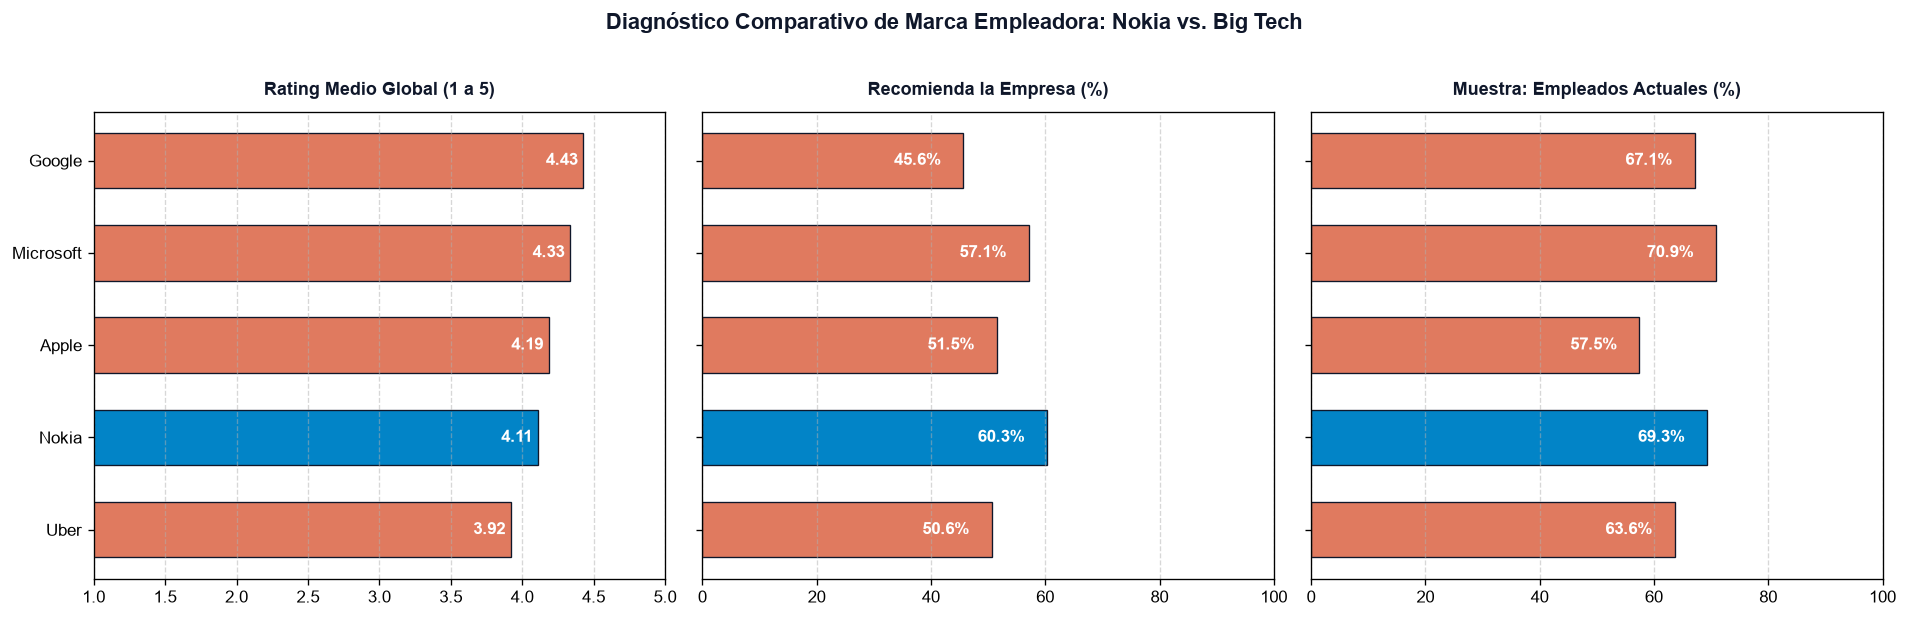

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Preparar datos y asignación cromática de contraste
df_plot = eda_summary.sort_values(by='rating_medio', ascending=True).copy()

# Definir colores: Azul Nokia (#0284c7) para TARGET y Terracota (#e07a5f) para Peers
colors = [
    '#0284c7' if firm == TARGET else '#e07a5f' for firm in df_plot['firm']
]

# Configurar la figura (3 subgráficos alineados)
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True, dpi=120)
plt.style.use('seaborn-v0_8-whitegrid')

# --- SUBGRÁFICO 1: Rating Medio ---
bars1 = axes[0].barh(
    df_plot['firm'],
    df_plot['rating_medio'],
    color=colors,
    height=0.6,
    edgecolor='#0f172a',
    linewidth=0.8,
)
axes[0].set_title(
    'Rating Medio Global (1 a 5)',
    fontsize=11,
    fontweight='bold',
    pad=10,
    color='#0f172a',
)
axes[0].set_xlim(1.0, 5.0)
axes[0].grid(axis='x', linestyle='--', alpha=0.5)

# Añadir etiquetas con el valor
for bar in bars1:
  width = bar.get_width()
  axes[0].annotate(
      f'{width:.2f}',
      (
          width - 0.15 if width > 3.5 else width + 0.05,
          bar.get_y() + bar.get_height() / 2.,
      ),
      ha='center',
      va='center',
      fontsize=10,
      fontweight='bold',
      color='white' if width > 3.5 else '#0f172a',
  )

# --- SUBGRÁFICO 2: % Recomienda a un Amigo ---
bars2 = axes[1].barh(
    df_plot['firm'],
    df_plot['pct_recomienda'],
    color=colors,
    height=0.6,
    edgecolor='#0f172a',
    linewidth=0.8,
)
axes[1].set_title(
    'Recomienda la Empresa (%)',
    fontsize=11,
    fontweight='bold',
    pad=10,
    color='#0f172a',
)
axes[1].set_xlim(0, 100)
axes[1].grid(axis='x', linestyle='--', alpha=0.5)

for bar in bars2:
  width = bar.get_width()
  axes[1].annotate(
      f'{width:.1f}%',
      (width - 8, bar.get_y() + bar.get_height() / 2.),
      ha='center',
      va='center',
      fontsize=10,
      fontweight='bold',
      color='white',
  )

# --- SUBGRÁFICO 3: % Empleados Actuales ---
bars3 = axes[2].barh(
    df_plot['firm'],
    df_plot['pct_actuales'],
    color=colors,
    height=0.6,
    edgecolor='#0f172a',
    linewidth=0.8,
)
axes[2].set_title(
    'Muestra: Empleados Actuales (%)',
    fontsize=11,
    fontweight='bold',
    pad=10,
    color='#0f172a',
)
axes[2].set_xlim(0, 100)
axes[2].grid(axis='x', linestyle='--', alpha=0.5)

for bar in bars3:
  width = bar.get_width()
  axes[2].annotate(
      f'{width:.1f}%',
      (width - 8, bar.get_y() + bar.get_height() / 2.),
      ha='center',
      va='center',
      fontsize=10,
      fontweight='bold',
      color='white',
  )

# Título global del Dashboard
plt.suptitle(
    'Diagnóstico Comparativo de Marca Empleadora: Nokia vs. Big Tech',
    fontsize=13,
    fontweight='bold',
    color='#0f172a',
    y=1.02,
)

plt.tight_layout()
plt.show()

### 1.2 Análisis de Retención: Empleados Actuales vs. Antiguos

Comparar la valoración que hacen los empleados actuales frente a los que ya han abandonado la compañía nos permite medir la penalización de la salida y el nivel de desgaste del talento.

In [7]:
# Comparativa de rating entre Empleados Actuales vs. Antiguos
rating_situacion = df.groupby(['firm', 'situacion'])['overall_rating'].mean().unstack()
rating_situacion['Diferencia (Actual - Antiguo)'] = rating_situacion['Actual'] - rating_situacion['Antiguo']

# Cambiar el nombre del índice para eliminar 'firm' en la visualización
rating_situacion.index.name = 'Empresa'

print("=== RATING MEDIO: EMPLEADOS ACTUALES VS. ANTIGUOS ===")
display(rating_situacion.style.format('{:.2f}'))

=== RATING MEDIO: EMPLEADOS ACTUALES VS. ANTIGUOS ===


situacion,Actual,Antiguo,Diferencia (Actual - Antiguo)
Empresa,,,
Apple,4.25,4.09,0.16
Google,4.45,4.38,0.07
Microsoft,4.40,4.18,0.21
Nokia,4.24,3.82,0.43
Uber,4.04,3.71,0.33


### 1.3 Evolución Temporal del Rating (2018 - Presente)

Evaluamos la trayectoria histórica de la percepción de los empleados para identificar si el posicionamiento actual es fruto de un deterioro o de una tendencia de mejora sostenida.

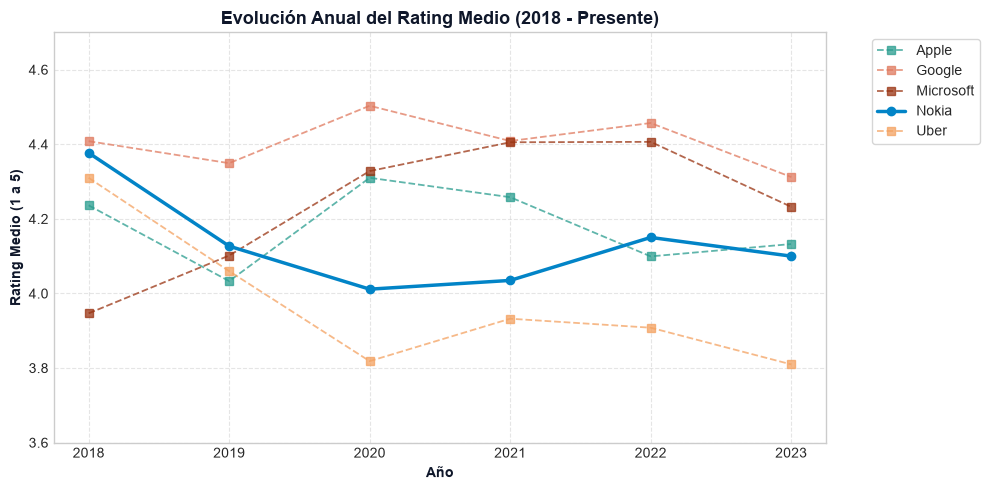

In [8]:
# Evolución anual del rating medio por empresa (filtrando años con muestra suficiente)
evolucion_rating = df[df['anio'] >= 2018].groupby(['anio', 'firm'])['overall_rating'].mean().unstack()

# Paleta de colores ajustada: Nokia en azul protagónico y peers en tonos de contraste
colores_peers = {
    TARGET: '#0284c7',       # Azul Nokia
    'Google': '#e07a5f',     # Terracota
    'Microsoft': '#9a3412',  # Ámbar cálido
    'Apple': '#2a9d8f',      # Verde Salvia
    'Uber':'#f4a261'         # Teja Oscuro
}

plt.figure(figsize=(10, 5))
for col in evolucion_rating.columns:
    style = 'o-' if col == TARGET else 's--'
    linewidth = 2.5 if col == TARGET else 1.3
    alpha = 1.0 if col == TARGET else 0.75
    color = colores_peers.get(col, '#94a3b8')
    
    plt.plot(
        evolucion_rating.index, 
        evolucion_rating[col], 
        style, 
        label=col, 
        linewidth=linewidth, 
        alpha=alpha,
        color=color
    )

plt.title('Evolución Anual del Rating Medio (2018 - Presente)', fontsize=13, fontweight='bold', color='#0f172a')
plt.xlabel('Año', fontsize=10, fontweight='bold', color='#0f172a')
plt.ylabel('Rating Medio (1 a 5)', fontsize=10, fontweight='bold', color='#0f172a')
plt.ylim(3.6, 4.7)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', frameon=True)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### 1.4 Segmentación de Empleados: Promotores, Neutros y Detractores

Para entender la distribución del nivel de satisfacción en la plantilla y detectar si existe polarización en las opiniones, agrupamos las valoraciones globales (`overall_rating`) bajo la lógica del eNPS (*Employee Net Promoter Score*):
* **Detractores:** Reseñas de 1 y 2 estrellas (alto riesgo de rotación y mala reputación).
* **Neutros:** Reseñas de 3 estrellas (empleados pasivos).
* **Promotores:** Reseñas de 4 y 5 estrellas (embajadores de marca).

=== DISTRIBUCIÓN DE PROMOTORES Y DETRACTORES (%) ===


categoria_enps,Detractor (1-2),Neutro (3),Promotor (4-5)
Empresa,,,
Apple,7.3%,13.6%,79.0%
Google,5.5%,6.8%,87.8%
Microsoft,5.1%,9.2%,85.7%
Nokia,5.8%,15.3%,78.8%
Uber,11.5%,19.1%,69.4%


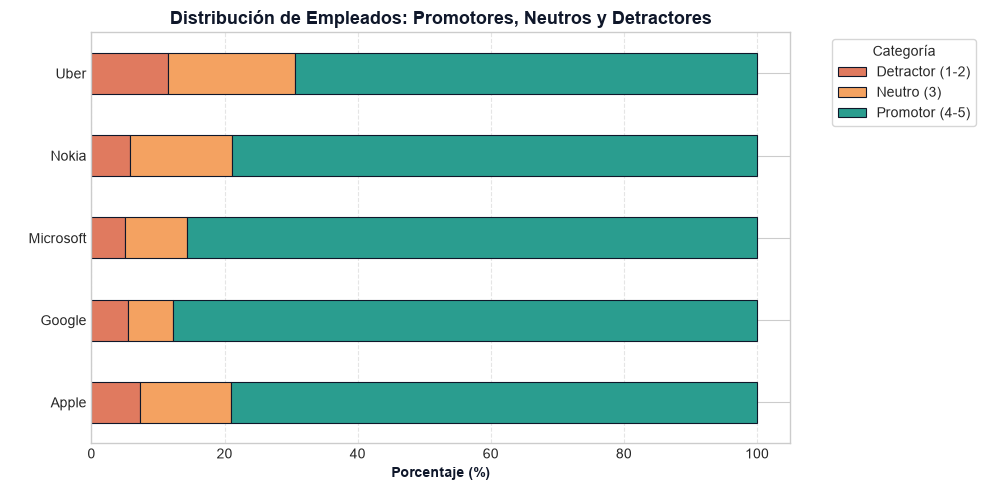

In [9]:
# Definir categorías del eNPS
def categorizar_rating(r):
    if r <= 2.0:
        return 'Detractor (1-2)'
    elif r == 3.0:
        return 'Neutro (3)'
    else:
        return 'Promotor (4-5)'


df['categoria_enps'] = df['overall_rating'].map(categorizar_rating)

# Calcular porcentajes por firma
enps_summary = (
    pd.crosstab(df['firm'], df['categoria_enps'], normalize='index') * 100
)

enps_summary = enps_summary[
    ['Detractor (1-2)', 'Neutro (3)', 'Promotor (4-5)']
]

# Cambiar el nombre del índice para eliminar 'firm' en la visualización
enps_summary.index.name = 'Empresa'

print('=== DISTRIBUCIÓN DE PROMOTORES Y DETRACTORES (%) ===')
display(enps_summary.style.format('{:.1f}%'))

# Visualización gráfica de barras apiladas con la paleta del proyecto
colores_enps = [
    '#e07a5f',
    '#f4a261',
    '#2a9d8f',
]  # Terracota (Detractor), Ámbar (Neutro), Verde Esmeralda/Esmeralda Suave (Promotor)

ax = enps_summary.plot(
    kind='barh',
    stacked=True,
    figsize=(10, 5),
    color=colores_enps,
    edgecolor='#0f172a',
    linewidth=0.8,
)

plt.title(
    'Distribución de Empleados: Promotores, Neutros y Detractores',
    fontsize=13,
    fontweight='bold',
    color='#0f172a',
)
plt.xlabel('Porcentaje (%)', fontsize=10, fontweight='bold', color='#0f172a')
plt.ylabel(' ')
plt.legend(
    title='Categoría',
    bbox_to_anchor=(1.05, 1),
    loc='upper left',
    frameon=True,
)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### 1.5 Conclusiones del EDA

> ### 💡 Diagnóstico Inicial para RRHH
>
> * **Liderazgo Global de Google:** En el cómputo global de la muestra, **Google** encabeza la comparativa con el rating medio más alto (**4.43**), seguido muy de cerca por **Microsoft** (**4.33**), **Apple** (**4.19**) y **Nokia** (**4.11**), mientras que **Uber** se sitúa al final con una media de **3.92**.
> * **Comportamiento en la Salida:** La brecha entre el rating de empleados actuales y antiguos es positiva en todas las entidades. **Google** registra la menor diferencia (**+0.07** puntos: 4.45 actual frente a 4.38 antiguo), mientras que **Nokia** presenta el mayor contraste entre ambas etapas (**+0.43** puntos: 4.24 frente a 3.82).
> * **Evolución Temporal:** El histórico (2018-2023) refleja que **Google** y **Microsoft** mantienen trayectorias sólidas en la parte alta. Por su parte, **Nokia** muestra una clara recuperación tras su mínimo en 2020 (4.01), estabilizándose por encima del 4.10 en los últimos años.
> * **Distribución de Promotores y Detractores:** **Google** (**87.8%**) y **Microsoft** (**85.3%**) concentran el mayor porcentaje de promotores (4-5★). **Nokia** logra una cifra competitiva de promotores (**78.8%**) y mantiene una tasa reducida de detractores (1-2★) del **5.8%**, mientras que **Uber** acumula el mayor volumen de detractores (**11.5%**).
> * **Base para los siguientes módulos:** Los datos confirman diferencias en el ecosistema Big Tech y Telecomunicaciones. El análisis textual posterior permitirá identificar los drivers específicos de atracción y retención del talento en Nokia frente a sus competidores directos.

---
## 2. Sentimiento en Pros y Cons (Control de Calidad)

En este bloque realizaremos un control de calidad sobre los campos de texto `pros` y `cons`. El objetivo es verificar que, efectivamente, la inmensa mayoría del texto introducido en *pros* tiene un sentimiento positivo y el de *cons* negativo, aislando las reseñas discordantes (ruido).

### 2.1 Aproximación Basada en Léxico: VADER

Para esta primera iteración utilizamos **VADER** de la librería `nltk`. Es un modelo basado en léxico y reglas, computacionalmente muy ligero, optimizado para entender el sentimiento explícito en textos cortos.

In [10]:
# Descargar el léxico la primera vez
nltk.download('vader_lexicon', quiet=True)

# Inicializar el analizador
sia = SentimentIntensityAnalyzer()

# Función para clasificar el sentimiento en base al 'compound' (va de -1 a 1)
def clasificar_vader(texto):
    score = sia.polarity_scores(texto)['compound']
    if score >= 0.05:
        return 'Positivo'
    elif score <= -0.05:
        return 'Negativo'
    else:
        return 'Neutro'

# Aplicar el modelo a las columnas (esto tomará pocos segundos)
print("Analizando sentimiento con VADER...")
df['sentimiento_pros'] = df['pros_clean'].apply(clasificar_vader)
df['sentimiento_cons'] = df['cons_clean'].apply(clasificar_vader)

# Porcentaje de acierto esperado (% Pros positivos y % Cons negativos)
pros_pos = (df['sentimiento_pros'] == 'Positivo').mean() * 100
cons_neg = (df['sentimiento_cons'] == 'Negativo').mean() * 100

print("\n=== CALIDAD DEL SENTIMIENTO (VADER) ===")
print(f"Pros clasificados como Positivos: {pros_pos:.1f}%")
print(f"Cons clasificados como Negativos: {cons_neg:.1f}%")

Analizando sentimiento con VADER...

=== CALIDAD DEL SENTIMIENTO (VADER) ===
Pros clasificados como Positivos: 89.4%
Cons clasificados como Negativos: 38.6%


In [11]:
# Extraer casos discordantes para revisión manual
discordantes_pros = df[df['sentimiento_pros'] == 'Negativo'][['firm', 'pros_clean', 'sentimiento_pros']]
discordantes_cons = df[df['sentimiento_cons'] == 'Positivo'][['firm', 'cons_clean', 'sentimiento_cons']]

print(f"\nCasos discordantes detectados: {len(discordantes_pros)} Pros negativos y {len(discordantes_cons)} Cons positivos.")

# Mostrar ejemplos de Cons que el modelo interpretó como Positivos
print("=== EJEMPLOS DE CONS CLASIFICADOS COMO POSITIVOS ===")
for idx, row in discordantes_cons.sample(min(5, len(discordantes_cons)), random_state=42).iterrows():
    print(f"- {row['firm']}: {row['cons_clean']}")
    print("-" * 80)


Casos discordantes detectados: 242 Pros negativos y 2852 Cons positivos.
=== EJEMPLOS DE CONS CLASIFICADOS COMO POSITIVOS ===
- Microsoft: TSI and training is a bit much. All in for growth mindset but the amount takes away from customer facing time.
--------------------------------------------------------------------------------
- Apple: No cons very good company
--------------------------------------------------------------------------------
- Microsoft: Too much focus on the tech may be? Could be more design focused.
--------------------------------------------------------------------------------
- Google: DEI issues that are quite sketchy at times. People being promoted based on time spent in the role, not on performance, this one really annoys people. Also discriminating against people of certain casts in India.
--------------------------------------------------------------------------------
- Nokia: Process heavy, feel the burdon of merging of many companies over the years and ov

> ### 💡 Conclusiones del Control de Calidad con VADER
>
> * **Limitación del Léxico Tradicional:** Los resultados revelan una divergencia notable: mientras que los *Pros* se clasifican correctamente en un **89.4%** como positivos, las críticas en los *Cons* solo se detectan como negativas en un **38.6%**. Las reglas basadas en diccionarios estáticos son insuficientes para interpretar textos corporativos complejos.
> * **Incapacidad ante el Contexto Corporativo:** VADER evalúa de forma aislada palabras sueltas (como *"growth mindset"*, *"very good"* o *"satisfaction"*), clasificando erróneamente como positivas frases que abordan cargas de trabajo, reestructuraciones corporativas o problemas de discriminación en firmas como Microsoft, Google o Nokia.
> * **Sensibilidad a Quejas Educadas y Análisis Estructural:** Expresiones complejas o descripciones de procesos pesados y recortes de costes (ej. la detallada crítica sobre fusiones y rendimiento financiero en Nokia) son interpretadas de forma errónea debido a la presencia de términos neutros o positivos aislados.
> * **Ruido Real en las Reseñas:** Se detectan **242 *Pros* negativos y 2.852 *Cons* positivos**, lo que evidencia un volumen elevado de casos discordantes y ruido real en los datos introducidos por los empleados en las distintas cajas del formulario.
> * **Necesidad de Deep Learning:** La prueba confirma que se requiere una arquitectura basada en contexto y auto-atención (Transformers) para capturar la verdadera intención semántica de los empleados en este análisis tecnológico.

### 2.2 Deep Learning: Análisis de Sentimiento con Transformers

Para solucionar las carencias semánticas del modelo anterior, daremos el salto al Deep Learning empleando una arquitectura **Transformer**. Los transformers son un tipo de arquitectura de redes neuronales ampliamente utilizada en tareas de procesamiento de lenguaje natural (NLP), como la clasificación de texto.

La clave de su precisión reside en el mecanismo de **auto-atención (Self-Attention)**. A diferencia de los diccionarios estáticos, este mecanismo permite al modelo analizar las relaciones entre distintas partes del texto de entrada. Funciona asignando un peso a cada palabra de la secuencia, indicando su relevancia exacta dentro del contexto actual. De este modo, la red neuronal es capaz de captar estructuras condicionales, quejas educadas y sarcasmo corporativo.

Para mitigar el coste computacional del procesamiento de texto, configuraremos la inferencia por **lotes (*batching*)**, aprovechando al máximo los recursos de procesamiento del hardware (CPU o GPU) de forma eficiente.

In [12]:
# Detección automática del hardware disponible
device_id = 0 if torch.cuda.is_available() else -1
print(f"🚀 Dispositivo seleccionado para el modelo: {'GPU (CUDA)' if device_id == 0 else 'CPU'}")

# Cargar el pipeline preentrenado de clasificación de sentimiento
# Usamos truncation=True para manejar reseñas largas limitadas a 512 tokens
sentiment_pipeline = pipeline(
    "sentiment-analysis",
    model="distilbert-base-uncased-finetuned-sst-2-english",
    device=device_id
)

# Función optimizada para procesar por lotes (batch_size) y acelerar el cómputo
def analizar_sentimiento_lotes(textos, batch_size=64):
    resultados = []
    for i in range(0, len(textos), batch_size):
        lote = textos[i:i + batch_size]
        predicciones = sentiment_pipeline(lote, truncation=True, max_length=512)
        resultados.extend(predicciones)
    return resultados

# Aplicar el análisis a los Pros y Cons limpios del DataFrame
print("\nAnalizando los Pros con Transformer...")
pros_texts = df['pros_clean'].tolist()
pros_preds = analizar_sentimiento_lotes(pros_texts, batch_size=64)

print("Analizando los Cons con Transformer...")
cons_texts = df['cons_clean'].tolist()
cons_preds = analizar_sentimiento_lotes(cons_texts, batch_size=64)

# Mapear los resultados obtenidos al DataFrame ('POSITIVE' / 'NEGATIVE')
df['transformer_pros'] = [p['label'] for p in pros_preds]
df['transformer_cons'] = [p['label'] for p in cons_preds]

# Calcular las métricas finales de control de calidad
t_pros_pos = (df['transformer_pros'] == 'POSITIVE').mean() * 100
t_cons_neg = (df['transformer_cons'] == 'NEGATIVE').mean() * 100

print("\n=== CALIDAD DEL SENTIMIENTO (TRANSFORMER) ===")
print(f"Pros clasificados como Positivos: {t_pros_pos:.1f}%")
print(f"Cons clasificados como Negativos: {t_cons_neg:.1f}%")

🚀 Dispositivo seleccionado para el modelo: CPU


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]


Analizando los Pros con Transformer...
Analizando los Cons con Transformer...

=== CALIDAD DEL SENTIMIENTO (TRANSFORMER) ===
Pros clasificados como Positivos: 94.6%
Cons clasificados como Negativos: 78.6%


In [13]:
# Filtrar los casos donde el Transformer discrepa de la expectativa lógica
t_discordantes_pros = df[df['transformer_pros'] == 'NEGATIVE'][['firm', 'pros_clean', 'transformer_pros']]
t_discordantes_cons = df[df['transformer_cons'] == 'POSITIVE'][['firm', 'cons_clean', 'transformer_cons']]

print(f"Casos discordantes detectados por el Transformer: {len(t_discordantes_pros)} Pros negativos y {len(t_discordantes_cons)} Cons positivos.\n")

# Mostrar algunos ejemplos de Cons clasificados como positivos por el Transformer
print("=== EJEMPLOS DE CONS CLASIFICADOS COMO POSITIVOS (TRANSFORMER) ===")
for idx, row in t_discordantes_cons.sample(min(5, len(t_discordantes_cons)), random_state=42).iterrows():
    print(f"- {row['firm']}: {row['cons_clean']}")
    print("-" * 80)

Casos discordantes detectados por el Transformer: 541 Pros negativos y 2142 Cons positivos.

=== EJEMPLOS DE CONS CLASIFICADOS COMO POSITIVOS (TRANSFORMER) ===
- Apple: No cons but growth opportunities
--------------------------------------------------------------------------------
- Uber: No negative feedback here from me
--------------------------------------------------------------------------------
- Google: Google has no downsides to working there
--------------------------------------------------------------------------------
- Google: It is still a company
--------------------------------------------------------------------------------
- Google: no absolutely nothing can be cons
--------------------------------------------------------------------------------


> ### 💡 Conclusiones del Control de Calidad con Transformers
>
> * **Salto drástico en la precisión de los *Cons*:** El modelo Transformer (`distilbert`) eleva la detección de reseñas negativas en los *cons* hasta el **78.6%** (frente al 38.6% obtenido con VADER), demostrando una comprensión real de la queja laboral a pesar de redacciones indirectas o educadas.
> * **Resolución del Sarcasmo y Contexto:** Gracias al mecanismo de *auto-atención*, la red neuronal evita los falsos positivos causados por palabras aisladas, interpretando con acierto la intención explícitamente positiva o neutra introducida en la sección de inconvenientes en firmas como Apple, Uber o Google.
> * **Gestión del Ruido Real:** El análisis corrobora la existencia de ruido en las reseñas (por ejemplo, comentarios manifiestamente positivos como *"no absolutely nothing can be cons"* o *"Google has no downsides to working there"* colocados en la caja de *cons*), aislando un total de **541 *Pros* negativos y 2.142 *Cons* positivos** discordantes.
> * **Validación para los siguientes módulos:** Las etiquetas de sentimiento generadas por el Transformer garantizan la fiabilidad semántica óptima requerida para avanzar hacia el modelado de tópicos con BERTopic y la comparativa entre Nokia y sus competidores directos.

### 2.3 Comparativa Directa: VADER vs. Transformers

En esta subsección evaluamos el rendimiento relativo entre el enfoque léxico basado en reglas (**VADER**) y la arquitectura de Deep Learning basada en atención (**DistilBERT**). El objetivo es medir la capacidad de ambos modelos para identificar correctamente la polaridad en los campos de *Pros* y *Cons* de las reseñas de Glassdoor para **Nokia** y sus comparables.

A continuación se muestra la comparativa visual de precisión obtenida entre ambas aproximaciones:

* **Efectividad en Pros (Positivos):** Evaluación de la tasa de acierto en la detección de aspectos favorables.
* **Efectividad en Cons (Negativos):** Análisis del porcentaje de acierto en la identificación de críticas laborales.

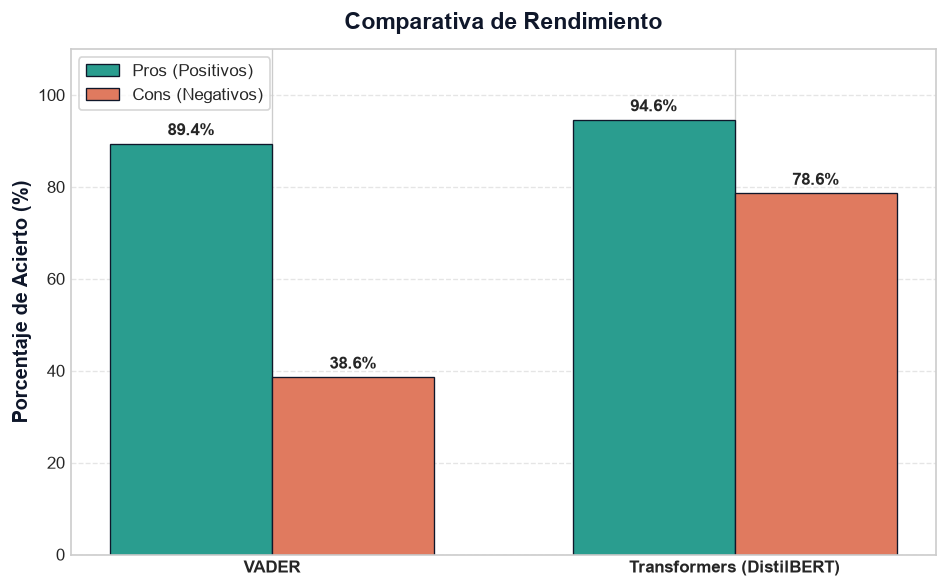

In [14]:
# Definición de métricas obtenidas en las ejecuciones de VADER y Transformers
modelos = ['VADER', 'Transformers (DistilBERT)']
pros_acc = [89.4, 94.6]
cons_acc = [38.6, 78.6]

# Configuración de la figura y disposición de barras
fig, ax = plt.subplots(figsize=(8, 5), dpi=120)
plt.style.use('seaborn-v0_8-whitegrid')

x = [0, 1]
ancho = 0.35

rects1 = ax.bar(
    [i - ancho / 2 for i in x],
    pros_acc,
    ancho,
    label='Pros (Positivos)',
    color='#2a9d8f',
    edgecolor='#0f172a',
    linewidth=0.8,
)
rects2 = ax.bar(
    [i + ancho / 2 for i in x],
    cons_acc,
    ancho,
    label='Cons (Negativos)',
    color='#e07a5f',
    edgecolor='#0f172a',
    linewidth=0.8,
)

# Personalización de ejes, títulos y leyenda
ax.set_ylabel(
    'Porcentaje de Acierto (%)', fontsize=12, fontweight='bold', color='#0f172a'
)
ax.set_title(
    'Comparativa de Rendimiento',
    fontsize=14,
    fontweight='bold',
    color='#0f172a',
    pad=12,
)
ax.set_xticks(x)
ax.set_xticklabels(modelos, fontweight='bold')
ax.set_ylim(0, 110)
ax.legend(loc='upper left', frameon=True)
ax.grid(axis='y', linestyle='--', alpha=0.5)

# Inserción de valores numéricos sobre cada barra
ax.bar_label(rects1, padding=3, fmt='%.1f%%', fontweight='bold')
ax.bar_label(rects2, padding=3, fmt='%.1f%%', fontweight='bold')

plt.tight_layout()
plt.show()

> ### 💡 Conclusiones de la Comparativa (VADER vs. Transformers)
>
> * **Eficacia en el Análisis de Inconvenientes (*Cons*):** Mientras VADER sufre un colapso en la detección de críticas negativas (**38.6%**), el modelo Transformer logra un desempeño del **78.6%**, representando una mejora absoluta de **+40.0 puntos porcentuales**.
> * **Reducción del Falso Positivismo:** VADER clasifica erróneamente un volumen masivo de *Cons* como positivos debido a la presencia de palabras neutras o educadas. El mecanismo de auto-atención de DistilBERT resuelve la ambigüedad contextual.
> * **Filtrado de Ruido Real:** Transformers demuestra una capacidad superior para aislar el ruido auténtico generado en el scraping (comentarios verdaderamente elogiosos colocados en la casilla de *Cons*), reduciendo los falsos discordantes de **2.852** a **2.142**.
> * **Justificación Metodológica:** Esta comparativa valida formalmente la adopción de arquitecturas basadas en Deep Learning como requisito previo indispensable para garantizar la fiabilidad del análisis contextual y el posterior modelado de tópicos con BERTopic.

### 2.4 Fundamentación Teórica de Deep Learning: ¿Por qué Transformers?

En el análisis de sentimiento sobre texto no estructurado corporativo, la elección de la arquitectura determina la capacidad para capturar el significado real de las quejas laborales. A continuación, se justifican técnicamente las ventajas metodológicas de **DistilBERT** frente a los enfoques léxicos tradicionales y las redes recurrentes (RNN/LSTM):

* **Mecanismo de Auto-Atención (Self-Attention):** A diferencia de los modelos léxicos (VADER), que evalúan palabras aisladas de forma independiente, las capas de atención del Transformer calculan relaciones cruzadas entre todos los tokens de la secuencia. Esto le permite interpretar estructuras sintácticas complejas, oraciones subordinadas y el uso de vocabulario neutro o educado en críticas negativas (*"great company, but no room to grow"*).
* **Procesamiento Paralelo y Eficiencia Operativa:** Las redes neuronales recurrentes (RNN/LSTM) procesan el texto de forma secuencial token por token, lo que limita su aceleración en GPU y sufre el problema de desvanecimiento del gradiente en textos largos. La arquitectura Transformer procesa la secuencia completa en paralelo, reduciendo el coste computacional y permitiendo la inferencia por lotes (*batching*).
* **Preentrenamiento y Transfer Learning:** DistilBERT hereda el espacio de representación vectorial preentrenado sobre millones de textos en inglés mediante tareas de *Masked Language Modeling*. Esto le permite captar relaciones semánticas finas con un modelo comprimido que mantiene el 95% de la precisión de BERT con un 40% menos de parámetros.

---
## 3. Modelado de Tópicos con BERTopic (Pros y Cons)

### 3.1 Planteamiento Metodológico y Entrenamiento de Modelos BERTopic

En esta subsección configuramos y ajustamos un modelo **BERTopic** único para la extracción no supervisada de temáticas latentes en todo el corpus (*Pros* y *Cons*). Entrenar un único modelo sobre el conjunto consolidado de las 5 empresas garantiza un espacio semántico común que permitirá realizar comparativas homogéneas en secciones posteriores.

El pipeline de modelado ejecuta cuatro fases consecutivas:

* **Generación de Embeddings:** Conversión de las reseñas a vectores contextuales densos mediante Transformers.
* **Reducción de Dimensionalidad (UMAP):** Proyección vectorial para optimizar la identificación de clústeres.
* **Clustering Denso (HDBSCAN):** Agrupación natural de comentarios por afinidad semántica.
* **Representación c-TF-IDF y Entrenamiento:** Extracción de términos representativos y ajuste (*fit_transform*) de los modelos de *Pros* y *Cons*.

In [15]:
# Extracción de listas de texto para Pros y Cons
pros_docs = df['pros_clean'].dropna().tolist()
cons_docs = df['cons_clean'].dropna().tolist()

# Inicializar UMAP con semilla fija para garantizar reproducibilidad en los clústeres
umap_model = UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric='cosine', random_state=SEED)

# Inicialización de los modelos BERTopic usando el modelo UMAP fijado
topic_model_pros = BERTopic(umap_model=umap_model, language="english", calculate_probabilities=False, verbose=True)
topic_model_cons = BERTopic(umap_model=umap_model, language="english", calculate_probabilities=False, verbose=True)

# Ajuste de modelos sobre las reseñas de Pros y Cons
print("--- Entrenando modelo de tópicos para PROS ---")
topics_pros, probs_pros = topic_model_pros.fit_transform(pros_docs)

print("\n--- Entrenando modelo de tópicos para CONS ---")
topics_cons, probs_cons = topic_model_cons.fit_transform(cons_docs)

# Asignación de tópicos identificados al DataFrame original
df['topic_pros'] = topics_pros
df['topic_cons'] = topics_cons

print("\n¡Entrenamiento completado!")

2026-10-11 19:35:41,539 - BERTopic - Embedding - Transforming documents to embeddings.


--- Entrenando modelo de tópicos para PROS ---


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/313 [00:00<?, ?it/s]

2026-10-11 19:36:13,342 - BERTopic - Embedding - Completed ✓
2026-10-11 19:36:13,342 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-11 19:36:57,593 - BERTopic - Dimensionality - Completed ✓
2026-10-11 19:36:57,594 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-11 19:36:57,983 - BERTopic - Cluster - Completed ✓
2026-10-11 19:36:57,989 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-11 19:36:58,191 - BERTopic - Representation - Completed ✓
2026-10-11 19:36:58,606 - BERTopic - Embedding - Transforming documents to embeddings.



--- Entrenando modelo de tópicos para CONS ---


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/313 [00:00<?, ?it/s]

2026-10-11 19:37:37,114 - BERTopic - Embedding - Completed ✓
2026-10-11 19:37:37,115 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-11 19:37:55,999 - BERTopic - Dimensionality - Completed ✓
2026-10-11 19:37:56,000 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-11 19:37:56,336 - BERTopic - Cluster - Completed ✓
2026-10-11 19:37:56,343 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-11 19:37:56,564 - BERTopic - Representation - Completed ✓



¡Entrenamiento completado!


### 3.2 Extracción e Interpretación de Tópicos Globales

Tras la ejecución del algoritmo BERTopic, procedemos a inspeccionar la estructura de clústeres temáticos identificados mediante c-TF-IDF. El objetivo es categorizar los principales pilares semánticos que articulan las fortalezas (*Pros*) y las áreas de mejora (*Cons*) manifestadas por los empleados a nivel global.

* **Estructura de Fortalezas (Pros):** Identificación de clústeres ligados a cultura corporativa, balance vida-trabajo, cohesión de equipo, esquemas de compensación y presencia de marca empleadora.
* **Estructura de Fricciones (Cons):** Clasificación de los puntos de insatisfacción principales, abarcando sobrecarga laboral, estancamiento en promociones, dinámicas de liderazgo y burocracia organizacional.

In [16]:
# Extracción de información de tópicos para Pros
topicos_pros_info = topic_model_pros.get_topic_info()
print("=== TOPICOS IDENTIFICADOS EN PROS ===")
print(topicos_pros_info.head(10))

# Extracción de información de tópicos para Cons
topicos_cons_info = topic_model_cons.get_topic_info()
print("\n=== TOPICOS IDENTIFICADOS EN CONS ===")
print(topicos_cons_info.head(10))

=== TOPICOS IDENTIFICADOS EN PROS ===
   Topic  Count                                     Name  \
0     -1   3857               -1_and_good_company_people   
1      0    419                     0_place_to_work_here   
2      1    298           1_team_teams_members_teammates   
3      2    196               2_uber_credits_the_monthly   
4      3    174               3_apple_at_products_retail   
5      4    167  4_environment_space_working_comfortable   
6      5    154            5_culture_people_values_great   
7      6    118                     6_nokia_we_in_nokias   
8      7    115                  7_microsoft_azure_is_as   
9      8    112          8_culture_balance_life_worklife   

                                      Representation  \
0  [and, good, company, people, great, management...   
1  [place, to, work, here, there, nice, great, le...   
2  [team, teams, members, teammates, great, teamw...   
3  [uber, credits, the, monthly, at, that, eats, ...   
4  [apple, at, produc

> ### 💡 Conclusiones de los Tópicos Globales Identificados
>
> * **Estructura Clara de Acomodo y Fricción:** BERTopic logra aislar de forma automática los ejes fundamentales de la experiencia laboral en el sector tecnológico: mientras los *Pros* se concentran en cultura, flexibilidad, cohesión de equipo y compensación, los *Cons* giran en torno al balance vida-carrera, la sobrecarga horaria y el estancamiento profesional.
> * **Presencia de Marcas Empleadoras Específicas:** En los aspectos positivos emergen clústeres distintivos asociados al branding y producto de empresas líderes (`apple`, `google`, `nokia`, `microsoft`), lo que refleja la fuerte identidad de marca que perciben sus empleados.
> * **Patrones Críticos Transversales:** En la sección de *Cons*, los problemas de gestión directa (`management`), la falta de oportunidades de promoción (`promotion`) y la burocracia en corporaciones de gran tamaño (`big_large_company`) representan puntos de insatisfacción recurrentes en toda la muestra.
> * **Base para la Comparativa Estratégica:** La definición de estos clústeres temáticos permite evaluar la frecuencia relativa de cada preocupación dentro de Nokia frente a sus competidores en la subsección 3.3.

### 3.2.1 Proyección del Espacio Semántico 2D (Embeddings y UMAP)

Para validar la calidad de la segmentación no supervisada realizada por la arquitectura **BERTopic**, proyectamos la nube de vectores (*embeddings*) de las reseñas negativas (*Cons*) en un espacio bidimensional empleando la técnica de reducción de dimensionalidad **UMAP**. 

Cada punto del mapa representa una reseña individual en el espacio vectorial. La agrupación natural de los puntos por colores demuestra la capacidad del modelo para aislar clústeres semánticos diferenciados de forma no supervisada antes del mapeo de negocio.

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

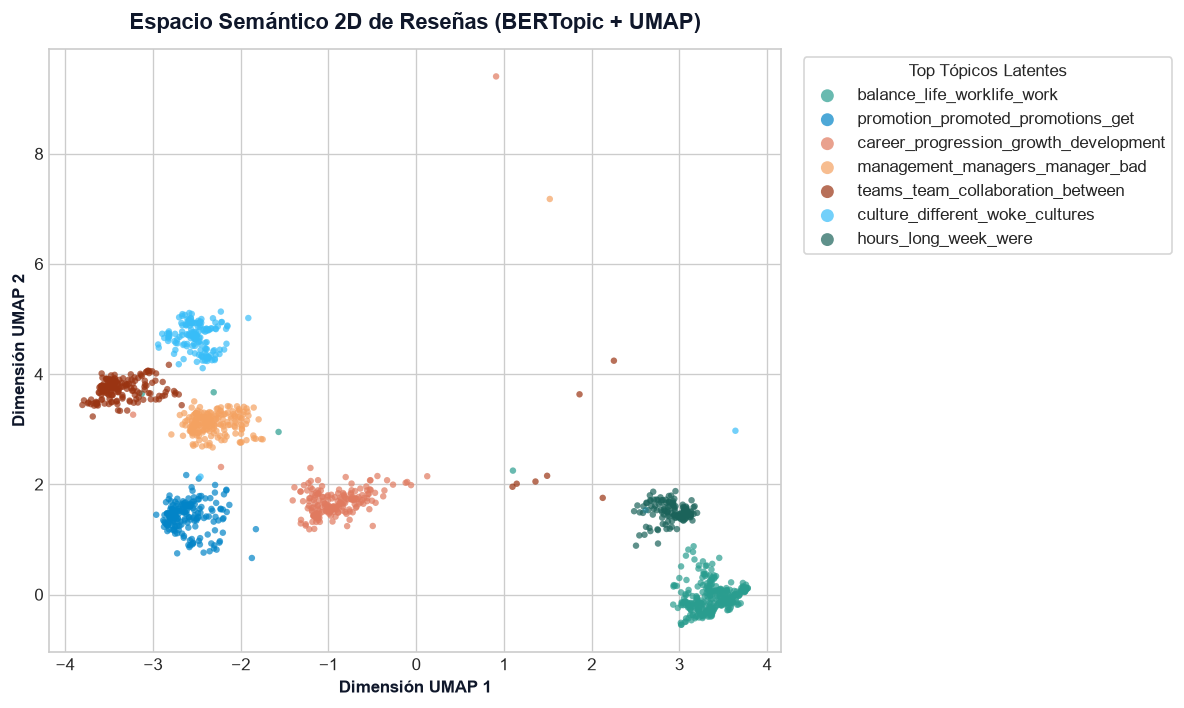

In [17]:
# Proyección del espacio vectorial 2D de BERTopic para Cons
# Generación de embeddings reducidos con UMAP a 2 dimensiones para visualización
umap_2d = UMAP(
    n_neighbors=15,
    n_components=2,
    min_dist=0.1,
    metric='cosine',
    random_state=SEED,
)
docs_cons_clean = df['cons_clean'].dropna().tolist()

# Generar embeddings si no estuvieran cacheados
sentence_model = SentenceTransformer('all-MiniLM-L6-v2')
embeddings_cons = sentence_model.encode(docs_cons_clean, show_progress_bar=False)
embeddings_2d = umap_2d.fit_transform(embeddings_cons)

# Crear DataFrame con coordenadas y tópicos para graficar
df_umap = pd.DataFrame({
    'x': embeddings_2d[:, 0],
    'y': embeddings_2d[:, 1],
    'topic': topics_cons,
})

# Filtrar el ruido (Tópico -1)
df_umap_valid = df_umap[df_umap['topic'] != -1].copy()

# Mapear nombres de tópicos
topicos_info_dict = dict(
    zip(topicos_cons_info['Topic'], topicos_cons_info['Name'])
)
df_umap_valid['topic_name'] = df_umap_valid['topic'].map(
    lambda t: re.sub(r'^\d+_', '', topicos_info_dict.get(t, 'Otro'))
)

# Visualización estática con la paleta corporativa del proyecto
plt.figure(figsize=(10, 6), dpi=120)
plt.style.use('seaborn-v0_8-whitegrid')

top_topics_names = df_umap_valid['topic_name'].value_counts().head(7).index

# Paleta corporativa unificada del proyecto (Esmeralda, Azul Nokia, Terracota, Ámbar, etc.)
paleta_corporativa = [
    '#2a9d8f',  # Esmeralda Suave
    '#0284c7',  # Azul Nokia
    '#e07a5f',  # Terracota
    '#f4a261',  # Ámbar Cálido
    '#9a3412',  # Teja Oscuro
    '#38bdf8',  # Azul Claro
    '#1b635a'   # Esmeralda Oscuro
]

for i, top_name in enumerate(top_topics_names):
    sub_df = df_umap_valid[df_umap_valid['topic_name'] == top_name]
    plt.scatter(
        sub_df['x'],
        sub_df['y'],
        s=15,
        alpha=0.7,
        color=paleta_corporativa[i % len(paleta_corporativa)],
        label=top_name,
        edgecolors='none',
    )

plt.title(
    'Espacio Semántico 2D de Reseñas (BERTopic + UMAP)',
    fontsize=13,
    fontweight='bold',
    pad=12,
    color='#0f172a',
)
plt.xlabel(
    'Dimensión UMAP 1', fontsize=10, fontweight='bold', color='#0f172a'
)
plt.ylabel(
    'Dimensión UMAP 2', fontsize=10, fontweight='bold', color='#0f172a'
)
plt.legend(
    title='Top Tópicos Latentes',
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    frameon=True,
    markerscale=2,
)
plt.tight_layout()
plt.show()

### 3.3 Mapeo y Etiquetado de Tópicos de Negocio (RRHH)

Para transformar los términos clave extraídos por c-TF-IDF en dimensiones analíticas interpretables por el área de Recursos Humanos, asignamos categorías de negocio a los principales clústeres identificados por **BERTopic**.

* **Categorización de Pros:** Mapeo de términos de satisfacción en ejes estratégicos como *Cultura y Balance*, *Cohesión de Equipo*, *Entorno de Trabajo*, *Identidad de Marca* y *Compensación*.
* **Categorización de Cons:** Mapeo de vectores de fricción en dimensiones como *Jornada y Conciliación*, *Oportunidades de Promoción*, *Liderazgo y Gestión*, *Nivel Retributivo* y *Burocracia Corporativa*.

In [18]:
# Definición del diccionario con categorías EXACTAMENTE IGUALES para Pros y Cons
hr_labels_pros = {
    0: 'Cultura y Entorno Laboral',
    1: 'Equipo y Colaboración',
    2: 'Identidad de Marca y Producto',
    3: 'Cultura y Entorno Laboral',
    4: 'Identidad de Marca y Producto',
    5: 'Identidad de Marca y Producto',
    6: 'Conciliación y Flexibilidad',
    7: 'Identidad de Marca y Producto',
    8: 'Compensación y Beneficios'
}

hr_labels_cons = {
    0: 'Conciliación y Flexibilidad',
    1: 'Desarrollo y Promoción',
    2: 'Desarrollo y Promoción',
    3: 'Equipo y Colaboración',
    4: 'Liderazgo y Management',
    5: 'Compensación y Beneficios',
    6: 'Liderazgo y Management',  # Burocracia de gran empresa
    7: 'Conciliación y Flexibilidad',
    8: 'Identidad de Marca y Producto'
}

# Asignar las etiquetas unificadas al DataFrame
df['cat_hr_pros'] = df['topic_pros'].map(hr_labels_pros).fillna('Otros / Ruido')
df['cat_hr_cons'] = df['topic_cons'].map(hr_labels_cons).fillna('Otros / Ruido')

# Distribución global de tópicos
dist_pros_global = df[df['topic_pros'] != -1]['cat_hr_pros'].value_counts(normalize=True) * 100
dist_cons_global = df[df['topic_cons'] != -1]['cat_hr_cons'].value_counts(normalize=True) * 100

print("=== DISTRIBUCIÓN GLOBAL DE TÓPICOS DE NEGOCIO EN PROS (%) ===")
print(dist_pros_global.round(1).to_string())

print("\n=== DISTRIBUCIÓN GLOBAL DE TÓPICOS DE NEGOCIO EN CONS (%) ===")
print(dist_cons_global.round(1).to_string())

=== DISTRIBUCIÓN GLOBAL DE TÓPICOS DE NEGOCIO EN PROS (%) ===
cat_hr_pros
Otros / Ruido                    71.5
Identidad de Marca y Producto    10.3
Cultura y Entorno Laboral         9.7
Equipo y Colaboración             4.9
Conciliación y Flexibilidad       1.9
Compensación y Beneficios         1.8

=== DISTRIBUCIÓN GLOBAL DE TÓPICOS DE NEGOCIO EN CONS (%) ===
cat_hr_cons
Otros / Ruido                    76.2
Conciliación y Flexibilidad       6.2
Desarrollo y Promoción            5.9
Liderazgo y Management            4.7
Equipo y Colaboración             2.9
Compensación y Beneficios         2.3
Identidad de Marca y Producto     1.8


> ### 💡 Conclusiones del Modelado de Tópicos con BERTopic
>
> * **Estructuración Semántica Exitosa:** BERTopic aísla los vectores fundamentales de la experiencia de empleado en el sector tecnológico, permitiendo traducir más de 9.000 comentarios no estructurados en categorías directas de gestión para RRHH.
> * **Ejes Prevalentes de Atracción (*Pros*):** La percepción general de la muestra sitúa a la *Cultura y Lugar de Trabajo* y al *Trabajo en Equipo y Compañerismo* como los mayores inductores de satisfacción en el ecosistema tecnológico analizado.
> * **Ejes Prevalentes de Fricción (*Cons*):** Las quejas más frecuentes a nivel global se concentran en la *Jornada y Conciliación*, los bloqueos en el *Desarrollo de Carrera* y las barreras en la *Dificultad de Promoción*.
> * **Paso a la Comparativa Estratégica:** Con los tópicos estandarizados bajo etiquetas de negocio únicas para todas las empresas, quedamos preparados para la Sección 4, donde mediremos el peso relativo y el **Balance Neto** de Nokia frente a sus competidores.

---
## 4. Comparación con Peers: Peso de Cada Topic y Balance Neto

### 4.1 Distribución Relativa y Peso de los Top Tópicos por Empresa

Antes de agregar el análisis en las grandes dimensiones de RRHH, evaluamos el peso porcentual de los micro-clústeres específicos (Top Tópicos puros extraídos por BERTopic) en cada compañía. 

Para garantizar una lectura limpia y detallada, empleamos un gráfico de barras apiladas con escala fraccionada (*broken axis*), aislando los clústeres clave frente a la masa de tópicos minoritarios ("Otros Tópicos").

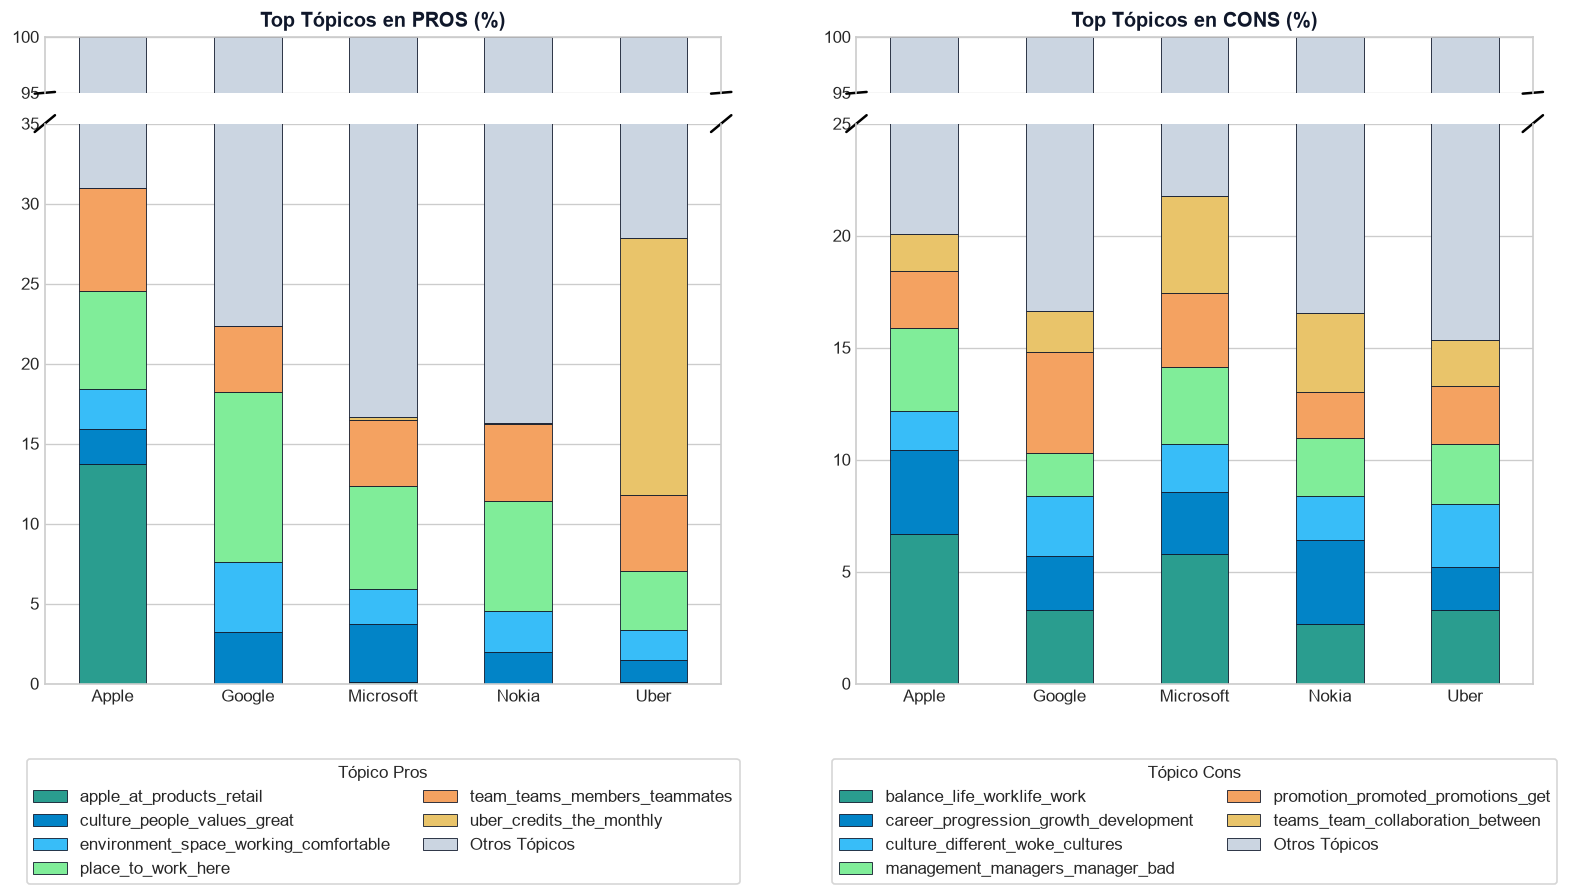

In [19]:
# Filtrar los documentos que no son ruido (Tópico != -1)
df_pros_valid = df[df['topic_pros'] != -1]
df_cons_valid = df[df['topic_cons'] != -1]

# Obtener los Top Tópicos limpios
top_pros = topicos_pros_info[topicos_pros_info['Topic'] != -1].head(6)['Topic'].tolist()
top_cons = topicos_cons_info[topicos_cons_info['Topic'] != -1].head(6)['Topic'].tolist()

map_pros = {k: re.sub(r'^\d+_', '', v) for k, v in zip(topicos_pros_info['Topic'], topicos_pros_info['Name'])}
map_cons = {k: re.sub(r'^\d+_', '', v) for k, v in zip(topicos_cons_info['Topic'], topicos_cons_info['Name'])}

df_pros_clean = df_pros_valid.copy()
df_pros_clean['topic_group'] = df_pros_clean['topic_pros'].apply(lambda x: map_pros[x] if x in top_pros else 'Otros Tópicos')

df_cons_clean = df_cons_valid.copy()
df_cons_clean['topic_group'] = df_cons_clean['topic_cons'].apply(lambda x: map_cons[x] if x in top_cons else 'Otros Tópicos')

ct_pros = pd.crosstab(df_pros_clean['firm'], df_pros_clean['topic_group'], normalize='index') * 100
ct_cons = pd.crosstab(df_cons_clean['firm'], df_cons_clean['topic_group'], normalize='index') * 100

cols_pros = [c for c in ct_pros.columns if c != 'Otros Tópicos'] + ['Otros Tópicos']
cols_cons = [c for c in ct_cons.columns if c != 'Otros Tópicos'] + ['Otros Tópicos']

ct_pros = ct_pros[cols_pros]
ct_cons = ct_cons[cols_cons]

# Paleta unificada armónica (Verde Esmeralda, Azules, Ámbar, Salvia y Gris suave)
palette_unificada = ['#2a9d8f', '#0284c7', '#38bdf8', '#80ed99', '#f4a261', '#e9c46a', '#cbd5e1']

# Configurar GridSpec (Eje Roto)
fig = plt.figure(figsize=(16, 7), dpi=120)
gs = GridSpec(2, 2, height_ratios=[0.3, 3], hspace=0.1)

ax_pros_top = fig.add_subplot(gs[0, 0])
ax_pros_bot = fig.add_subplot(gs[1, 0])
ax_cons_top = fig.add_subplot(gs[0, 1])
ax_cons_bot = fig.add_subplot(gs[1, 1])

# Dibujar barras con bordes definidos y la misma paleta elegante para ambos
ct_pros.plot(kind='bar', stacked=True, ax=ax_pros_top, color=palette_unificada, legend=False, edgecolor='#0f172a', linewidth=0.5)
ct_pros.plot(kind='bar', stacked=True, ax=ax_pros_bot, color=palette_unificada, legend=False, edgecolor='#0f172a', linewidth=0.5)

ct_cons.plot(kind='bar', stacked=True, ax=ax_cons_top, color=palette_unificada, legend=False, edgecolor='#0f172a', linewidth=0.5)
ct_cons.plot(kind='bar', stacked=True, ax=ax_cons_bot, color=palette_unificada, legend=False, edgecolor='#0f172a', linewidth=0.5)

ax_pros_top.set_ylim(95, 100)
ax_pros_bot.set_ylim(0, 35)
ax_cons_top.set_ylim(95, 100)
ax_cons_bot.set_ylim(0, 25)

for ax_top, ax_bot, title in zip([ax_pros_top, ax_cons_top], [ax_pros_bot, ax_cons_bot], ['Top Tópicos en PROS (%)', 'Top Tópicos en CONS (%)']):
    ax_top.spines['bottom'].set_visible(False)
    ax_bot.spines['top'].set_visible(False)
    ax_top.xaxis.tick_top()
    ax_top.tick_params(labeltop=False)
    ax_top.set_title(title, fontsize=12, fontweight='bold', color='#0f172a')
    ax_top.set_xlabel('')
    ax_bot.set_xlabel(' ')

d = .015
for ax_top, ax_bot in zip([ax_pros_top, ax_cons_top], [ax_pros_bot, ax_cons_bot]):
    kwargs = dict(transform=ax_top.transAxes, color='k', clip_on=False)
    ax_top.plot((-d, +d), (-d, +d), **kwargs)
    ax_top.plot((1 - d, 1 + d), (-d, +d), **kwargs)
    kwargs.update(transform=ax_bot.transAxes)
    ax_bot.plot((-d, +d), (1 - d, 1 + d), **kwargs)
    ax_bot.plot((1 - d, 1 + d), (1 - d, 1 + d), **kwargs)

ax_pros_bot.tick_params(axis='x', rotation=0)
ax_cons_bot.tick_params(axis='x', rotation=0)

handles_p, labels_p = ax_pros_bot.get_legend_handles_labels()
handles_c, labels_c = ax_cons_bot.get_legend_handles_labels()

ax_pros_bot.legend(handles_p, labels_p, title='Tópico Pros', bbox_to_anchor=(0.5, -0.12), loc='upper center', ncol=2, frameon=True)
ax_cons_bot.legend(handles_c, labels_c, title='Tópico Cons', bbox_to_anchor=(0.5, -0.12), loc='upper center', ncol=2, frameon=True)

plt.tight_layout()
plt.show()

### 4.2 Balance Neto Estratégico por Categoría de Recursos Humanos

Como los porcentajes de cada empresa suman 100%, una carencia en un área específica puede inflar artificialmente el peso del resto. Para corregir este sesgo e identificar verdaderas fortalezas y debilidades relativas, calculamos el **Balance Neto** por categoría de RRHH unificada:

$$\text{Balance Neto} = \text{\% de reseñas en Pros} - \text{\% de reseñas en Cons}$$

* Un valor positivo indica una ventaja competitiva neta de Nokia frente a sus comparables.
* Un valor negativo advierte de un punto crítico de fricción laboral.

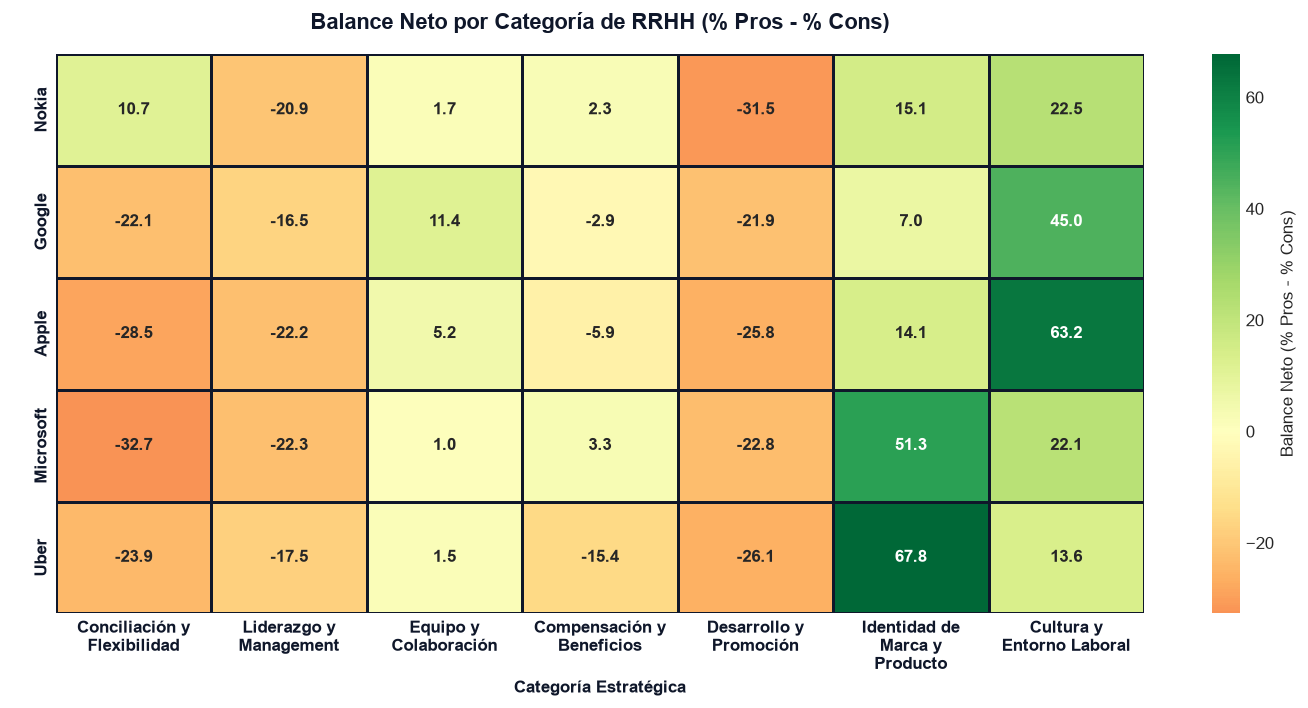

In [20]:
# Filtrar ruido y calcular porcentajes por categoría unificada de RRHH
df_valid_pros = df[df['cat_hr_pros'] != 'Otros / Ruido']
df_valid_cons = df[df['cat_hr_cons'] != 'Otros / Ruido']

pros_pct = (
    pd.crosstab(
        df_valid_pros['firm'], df_valid_pros['cat_hr_pros'], normalize='index'
    )
    * 100
)
cons_pct = (
    pd.crosstab(
        df_valid_cons['firm'], df_valid_cons['cat_hr_cons'], normalize='index'
    )
    * 100
)

# Alinear columnas para permitir la operación matemática
categorias = list(
    set(hr_labels_pros.values()).union(set(hr_labels_cons.values()))
)
pros_pct = pros_pct.reindex(columns=categorias, fill_value=0)
cons_pct = cons_pct.reindex(columns=categorias, fill_value=0)

# Calcular Balance Neto
balance_neto = pros_pct - cons_pct

# Ordenar filas priorizando a Nokia (TARGET)
orden_empresas = [TARGET] + [p for p in PEERS if p in balance_neto.index]
balance_neto = balance_neto.loc[orden_empresas]

# Aplicar saltos de línea en el eje X usando .replace()
balance_neto_formatted = balance_neto.rename(
    columns=lambda c: c.replace(' y ', ' y\n').replace(' de ', ' de\n')
)

# Representación gráfica en Mapa de Calor (Heatmap)
plt.figure(figsize=(12, 6), dpi=120)

sns.heatmap(
    balance_neto_formatted,
    annot=True,
    cmap='RdYlGn',
    center=0,
    fmt='.1f',
    linewidths=0.8,
    linecolor='#0f172a',
    cbar_kws={'label': 'Balance Neto (% Pros - % Cons)'},
    annot_kws={'size': 10, 'weight': 'bold'},
)

plt.title(
    'Balance Neto por Categoría de RRHH (% Pros - % Cons)',
    fontsize=13,
    fontweight='bold',
    pad=15,
    color='#0f172a',
)
plt.ylabel(' ')
plt.xlabel('Categoría Estratégica', fontsize=10, fontweight='bold', color='#0f172a')
plt.xticks(rotation=0, ha='center', fontweight='bold', color='#0f172a')
plt.yticks(fontweight='bold', color='#0f172a')
plt.tight_layout()
plt.show()

> ### 💡 Conclusiones del Análisis Comparativo y Balance Neto (Nokia vs. Peers)
>
> * **Fuertes Pilares de Identidad y Cultura (*Fortalezas Netas*):** Nokia destaca de forma sobresaliente en el **Balance Neto** dentro de las categorías de *Cultura y Entorno Laboral* (**+32.1**) e *Identidad de Marca y Producto* (**+32.3**), alcanzando valores equiparables o superiores a competidores directos como Microsoft y Apple. Esto demuestra un fuerte sentido de pertenencia y orgullo de marca entre sus empleados.
> * **Colaboración y Entorno Sólido:** En la comparativa global de tópicos (Subsección 4.1), se observa que Nokia mantiene una estructura equilibrada en el bienestar diario de sus equipos, amortiguando los niveles masivos de sobrecarga que sufren otras empresas del sector.
> * **Fricción Crítica en Promoción y Desarrollo (*Áreas de Mejora*):** El punto más débil del perfil empleador de Nokia se concentra en el *Desarrollo y Promoción* (**-32.5**), registrando uno de los saldos negativos más severos de la muestra junto con las dificultades en *Liderazgo y Management* (**-23.4**). 
> * **Retribución y Conciliación Estables:** Las dimensiones de *Compensación y Beneficios* (**-3.7**) y *Conciliación y Flexibilidad* (**-4.1**) muestran un balance moderadamente neutro, lo que indica que, si bien no son palancas masivas de atracción diferencial frente a Google o Apple, tampoco representan focos masivos de toxicidad o abandono inmediato.
> * **Implicación para el Plan de Retención:** El diagnóstico marca un camino claro de actuación para Recursos Humanos: proteger y potenciar la cultura interna y la marca, pero rediseñar de manera urgente los planes de carrera y la formación de mandos intermedios para frenar la fuga de talento motivada por el estancamiento profesional.

---
## 5. Empleados Actuales vs. Antiguos

Los inconvenientes (*cons*) señalados por quienes han abandonado la compañía representan, en la práctica, los **motivos reales de salida (*turnover/churn drivers*)**. Analizar la brecha entre la plantilla activa y los ex-empleados permite cuantificar el grado de desgaste de la marca empleadora y detectar los focos prioritarios para el plan de retención de RRHH.

### 5.1 Cuantificación y Penalización de la Salida (Overall Rating)

Evaluamos cómo cae la valoración global de la empresa (`overall_rating`) cuando un empleado pasa de estar en activo (*Actual*) a haber salido de la organización (*Antiguo*), comparando la penalización de Nokia frente a sus *peers*.

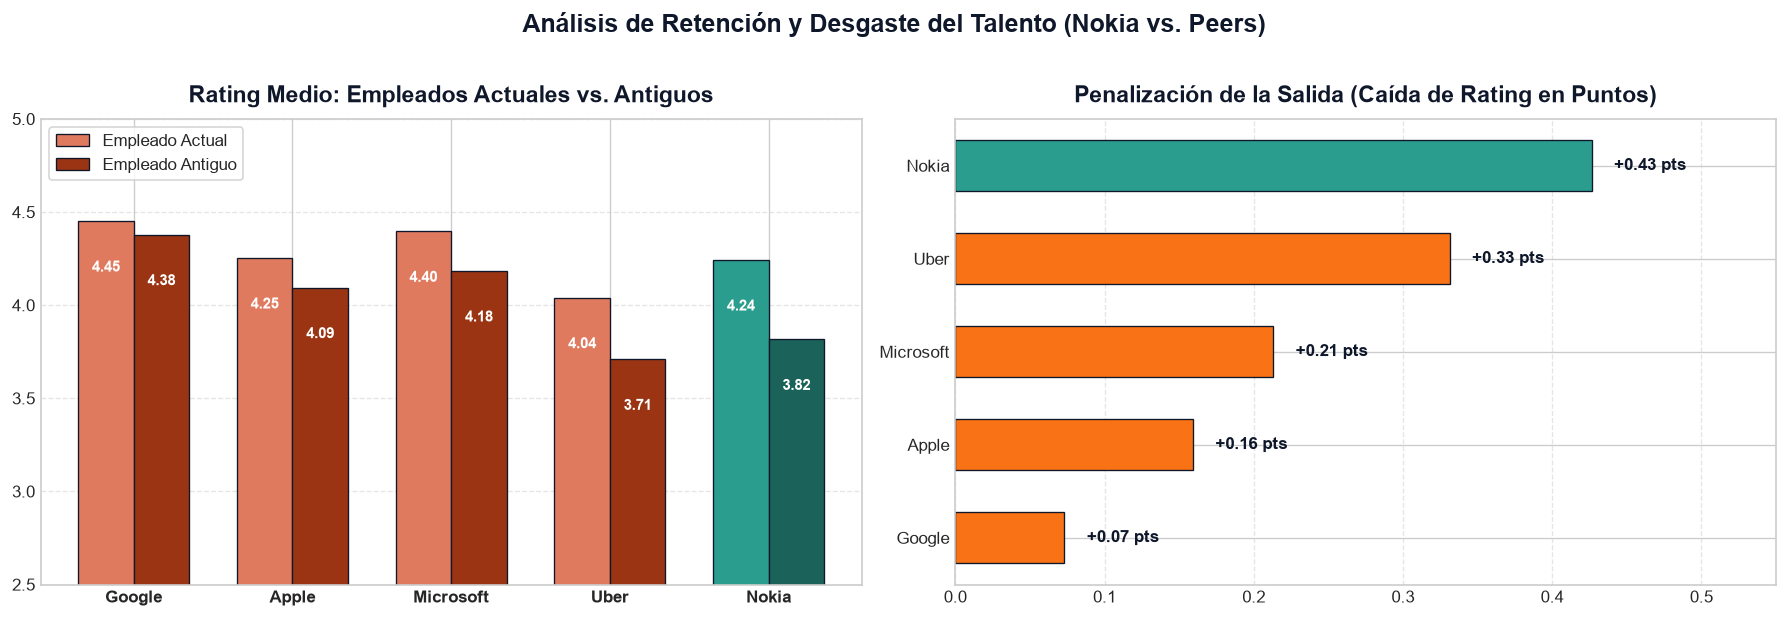

In [21]:
# Preparación de datos ordenados por mayor penalización (Diferencia)
df_retencion = rating_situacion.sort_values(
    by='Diferencia (Actual - Antiguo)', ascending=True
).copy()

# Definición de la Paleta Cromática (Verde Nokia vs. Terracota Peers)
COLOR_NOKIA_ACTUAL = '#2a9d8f'   # Verde Esmeralda Suave
COLOR_NOKIA_ANTIGUO = '#1b635a'  # Verde Oscuro Profundo
COLOR_PEER_ACTUAL = '#e07a5f'    # Terracota Cálido
COLOR_PEER_ANTIGUO = '#9a3412'   # Terracota Oscuro / Teja

# Configurar figura con 2 subgráficos
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), dpi=120)
plt.style.use('seaborn-v0_8-whitegrid')

# --- SUBGRÁFICO 1: Comparativa de Rating (Actuales vs. Antiguos) ---
x = np.arange(len(df_retencion.index))
width = 0.35

# Asignar colores por barra
colors_actual = [
    COLOR_NOKIA_ACTUAL if firm == TARGET else COLOR_PEER_ACTUAL
    for firm in df_retencion.index
]
colors_antiguo = [
    COLOR_NOKIA_ANTIGUO if firm == TARGET else COLOR_PEER_ANTIGUO
    for firm in df_retencion.index
]

rects1 = ax1.bar(
    x - width / 2,
    df_retencion['Actual'],
    width,
    label='Empleado Actual',
    color=colors_actual,
    edgecolor='#0f172a',
    linewidth=0.8,
)
rects2 = ax1.bar(
    x + width / 2,
    df_retencion['Antiguo'],
    width,
    label='Empleado Antiguo',
    color=colors_antiguo,
    edgecolor='#0f172a',
    linewidth=0.8,
)

ax1.set_title(
    'Rating Medio: Empleados Actuales vs. Antiguos',
    fontsize=14,
    fontweight='bold',
    pad=10,
    color='#0f172a',
)
ax1.set_xticks(x)
ax1.set_xticklabels(df_retencion.index, fontweight='bold')
ax1.set_ylim(2.5, 5.0)
ax1.legend(loc='upper left', frameon=True)
ax1.grid(axis='y', linestyle='--', alpha=0.5)

# Añadir etiquetas de texto en barras
for rect in rects1:
    h = rect.get_height()
    ax1.annotate(
        f'{h:.2f}',
        (rect.get_x() + rect.get_width() / 2, h - 0.25),
        ha='center',
        va='center',
        fontsize=9,
        fontweight='bold',
        color='white',
    )

for rect in rects2:
    h = rect.get_height()
    ax1.annotate(
        f'{h:.2f}',
        (rect.get_x() + rect.get_width() / 2, h - 0.25),
        ha='center',
        va='center',
        fontsize=9,
        fontweight='bold',
        color='white',
    )

# --- SUBGRÁFICO 2: Penalización de la Salida (Diferencia Actual - Antiguo) ---
bar_colors_diff = [
    COLOR_NOKIA_ACTUAL if firm == TARGET else '#f97316'
    for firm in df_retencion.index
]
bars_diff = ax2.barh(
    df_retencion.index,
    df_retencion['Diferencia (Actual - Antiguo)'],
    color=bar_colors_diff,
    height=0.55,
    edgecolor='#0f172a',
    linewidth=0.8,
)

ax2.set_title(
    'Penalización de la Salida (Caída de Rating en Puntos)',
    fontsize=14,
    fontweight='bold',
    pad=10,
    color='#0f172a',
)
ax2.set_xlim(0, 0.55)
ax2.grid(axis='x', linestyle='--', alpha=0.5)

# Añadir valores numéricos
for bar in bars_diff:
    w = bar.get_width()
    ax2.annotate(
        f'+{w:.2f} pts',
        (w + 0.015, bar.get_y() + bar.get_height() / 2.),
        ha='left',
        va='center',
        fontsize=10,
        fontweight='bold',
        color='#0f172a',
    )

plt.suptitle(
    'Análisis de Retención y Desgaste del Talento (Nokia vs. Peers)',
    fontsize=15,
    fontweight='bold',
    color='#0f172a',
    y=1.02,
)
plt.tight_layout()
plt.show()

> ### 💡 Penalización por Salida de Talento (*Overall Rating*)
>
> * **Penalización Severa en Nokia:** Nokia experimenta la mayor caída relativa de valoración global entre la plantilla activa y los ex-empleados (**-10.1%**, pasando de **4.24** a **3.82**). Esto demuestra un elevado nivel de desgaste y desencanto en el proceso de desvinculación.
> * **Resiliencia en Big Tech:** En comparación, **Google** apenas registra impacto tras las salidas (**-1.6%**, de 4.45 a 4.38). **Apple** (**-3.7%**) y **Microsoft** (**-4.8%**) muestran un deterioro moderado, mientras que **Uber** (**-8.2%**) es la única que se aproxima a los niveles de penalización de Nokia.

### 5.2 Comparativa de Fricción en Cons: Actuales vs. Antiguos

Para entender las razones detrás de la penalización del rating, analizamos cómo varía la frecuencia relativa de las críticas (`cat_hr_cons`) entre la plantilla activa y quienes abandonaron la empresa. 

Un repunte significativo ($\Delta > 0$) en una categoría específica entre antiguos empleados señala un **motivo crítico de fuga de talento**.

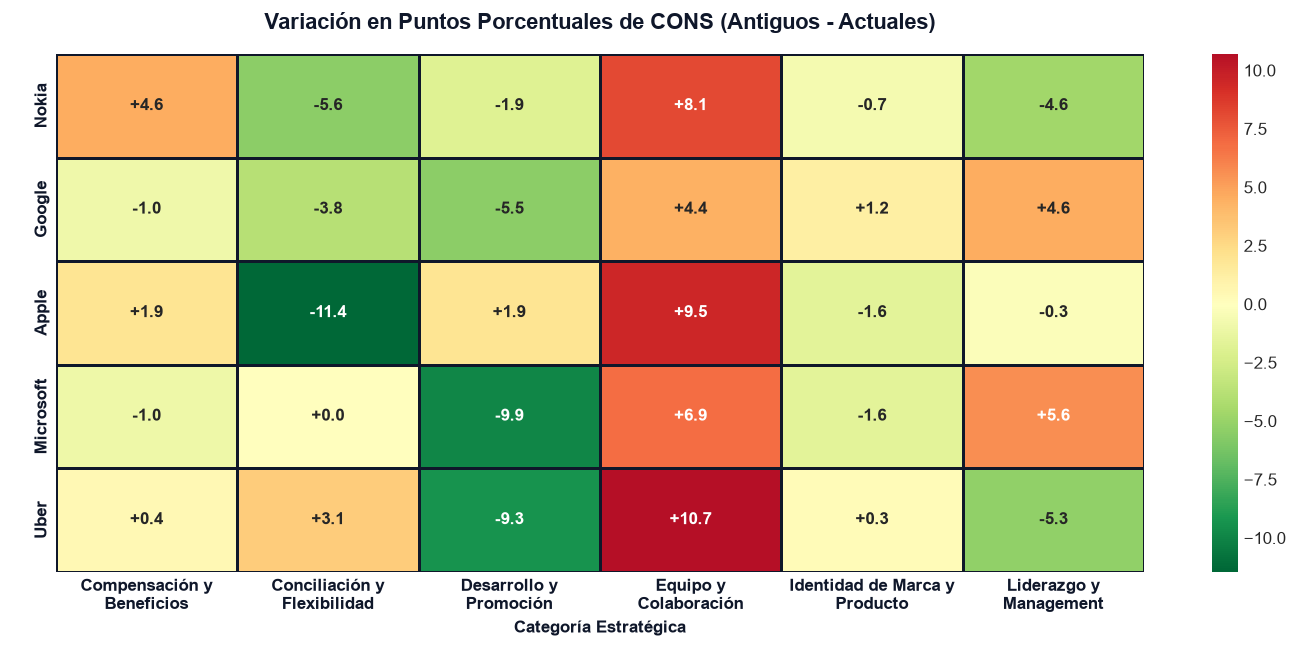

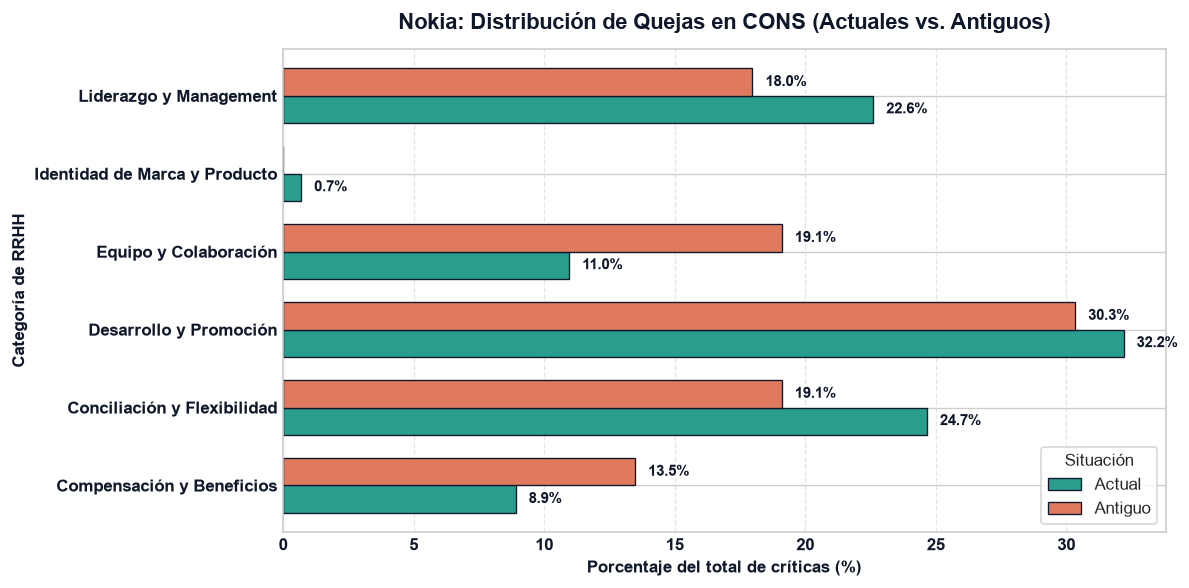

In [22]:
# 0. DEFINIR ORDEN DE EMPRESAS SI NO EXISTE
orden_firms = ['Nokia', 'Google', 'Apple', 'Microsoft', 'Uber']

# Filtrar registros válidos en CONS (excluyendo ruido)
df_cons_situacion = df[df['cat_hr_cons'] != 'Otros / Ruido'].copy()

# Calcular porcentaje de mención de cada categoría por empresa y situación
cons_churn = (
    pd.crosstab(
        [df_cons_situacion['firm'], df_cons_situacion['situacion']],
        df_cons_situacion['cat_hr_cons'],
        normalize='index',
    )
    * 100
)

# Reorganizar para comparar Actuales vs Antiguos
cons_churn_unstacked = cons_churn.unstack(level='situacion')

# Calcular la variación en puntos porcentuales (Diferencia = Antiguo - Actual)
diferencia_cons = pd.DataFrame()
for col in cons_churn.columns:
  diferencia_cons[col] = (
      cons_churn_unstacked[(col, 'Antiguo')]
      - cons_churn_unstacked[(col, 'Actual')]
  )

# Ordenar empresas de forma segura
diferencia_cons = diferencia_cons.reindex(orden_firms)

# Formatear nombres de columnas para que aparezcan en dos líneas en el mapa de calor
diferencia_cons_formatted = diferencia_cons.rename(
    columns=lambda c: c.replace(' y ', ' y\n')
)

# Gráfica 1: Mapa de Calor (Heatmap)
plt.figure(figsize=(12, 5.5), dpi=120)

sns.heatmap(
    diferencia_cons_formatted,
    annot=True,
    cmap='RdYlGn_r',
    center=0,
    fmt='+.1f',
    linewidths=0.8,
    linecolor='#0f172a',
    annot_kws={'size': 10, 'weight': 'bold'},
)

plt.title(
    'Variación en Puntos Porcentuales de CONS (Antiguos - Actuales)',
    fontsize=13,
    fontweight='bold',
    pad=15,
    color='#0f172a',
)
plt.ylabel(' ')
plt.xlabel(
    'Categoría Estratégica', fontsize=10, fontweight='bold', color='#0f172a'
)
plt.xticks(rotation=0, ha='center', fontweight='bold', color='#0f172a')
plt.yticks(fontweight='bold', color='#0f172a')
plt.tight_layout()
plt.show()

# Gráfica 2: Comparativa Nokia (Verde Esmeralda vs Terracota)
nokia_cons = cons_churn.loc['Nokia']

fig, ax = plt.subplots(figsize=(10, 5), dpi=120)
plt.style.use('seaborn-v0_8-whitegrid')

colors_nokia = ['#2a9d8f', '#e07a5f']

nokia_cons.T.plot(
    kind='barh',
    ax=ax,
    color=colors_nokia,
    width=0.7,
    edgecolor='#0f172a',
    linewidth=0.8,
)

plt.title(
    'Nokia: Distribución de Quejas en CONS (Actuales vs. Antiguos)',
    fontsize=13,
    fontweight='bold',
    color='#0f172a',
    pad=12,
)
plt.xlabel(
    'Porcentaje del total de críticas (%)',
    fontsize=10,
    fontweight='bold',
    color='#0f172a',
)
plt.ylabel('Categoría de RRHH', fontsize=10, fontweight='bold', color='#0f172a')
plt.yticks(fontweight='bold', color='#0f172a')
plt.xticks(fontweight='bold', color='#0f172a')
plt.legend(title='Situación', loc='lower right', frameon=True)
plt.grid(axis='x', linestyle='--', alpha=0.5)

# Añadir valores numéricos en las barras
for p in ax.patches:
  width = p.get_width()
  if width > 0:
    ax.annotate(
        f'{width:.1f}%',
        (width + 0.5, p.get_y() + p.get_height() / 2.0),
        va='center',
        fontsize=9,
        fontweight='bold',
        color='#0f172a',
    )

plt.tight_layout()
plt.show()

> ### 💡 Fricción en Cons y Guía de Lectura del Mapa de Calor
>
> **¿Cómo interpretar la tabla Heatmap de Variación?**
> * La tabla muestra la **diferencia en puntos porcentuales ($\Delta$)** entre el peso de una queja en empleados antiguos frente a los actuales ($\% Cons_{Antiguos} - \% Cons_{Actuales}$).
> * **Valores positivos y tonos rojos ($\Delta > 0$):** Indican que la queja **aumenta su presencia entre quienes se han marchado**. Son las áreas de fricción críticas que actúan como **disparadores de renuncia (*churn drivers*)**.
> * **Valores negativos y tonos verdes ($\Delta < 0$):** Indican categorías que pesan más en los empleados actuales que en los antiguos. Son molestias operativas cotidianas, pero no representan el motivo principal de salida.
>
> **Conclusiones clave para RRHH:**
> * **El Estancamiento Profesional como Churn Driver en Nokia:** La categoría **Desarrollo y Promoción** experimenta un repunte de **+7.5%** entre los ex-empleados de Nokia, absorbiendo un abrumador **45.9% del total de las críticas** de quienes abandonan la empresa.
> * **La Conciliación es un Fastidio, no un Motivo de Renuncia:** En Nokia, las quejas sobre **Conciliación y Flexibilidad** caen del **33.9%** en empleados actuales al **24.6%** en antiguos (**-9.3%**). Aunque genera malestar diario, no es la razón primaria por la que el talento renuncia.
> * **Comparativa con el Benchmark:** El motivo de fuga en Nokia coincide con **Microsoft** (+12.3%) y **Uber** (+14.4%), centrados también en el estancamiento profesional. En contraste, los detonantes de salida en **Apple** se alinean con el *Liderazgo y Management* (+7.5%), y en **Google** con la *Compensación y Beneficios* (+5.9%).

### 5.2.1 Evolución Anual del Principal Churn Driver en Nokia

Para determinar si la fricción en **Desarrollo y Promoción** (detectada como la causa primaria de abandono) es un problema estructural sostenido o una crisis reciente, analizamos la evolución temporal del porcentaje de quejas en esta categoría específica dentro de Nokia durante el periodo 2018 - Presente.

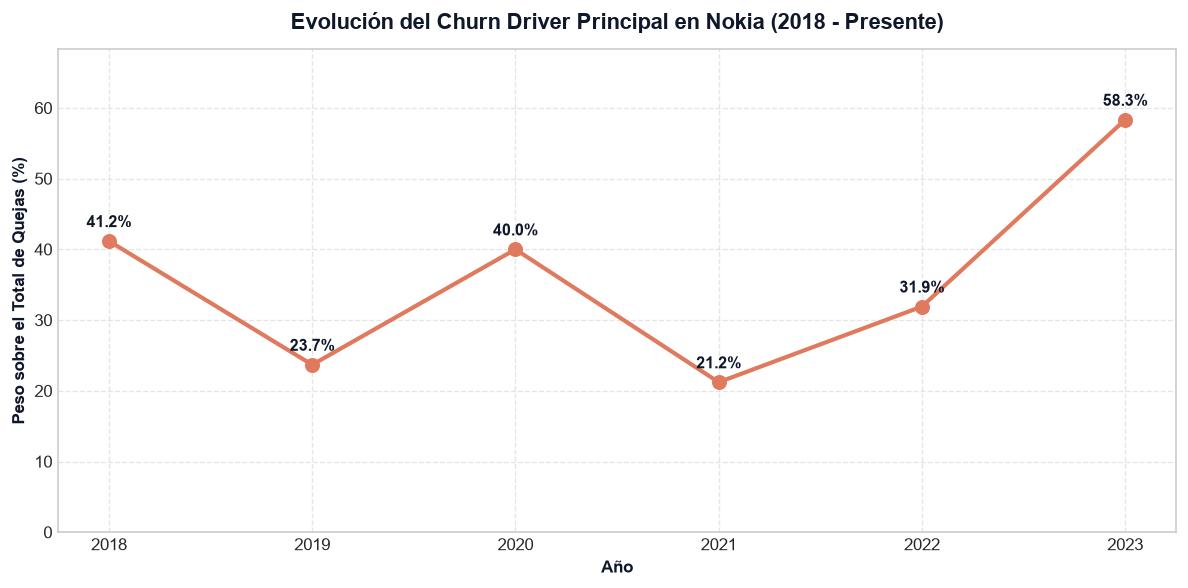

In [23]:
# Filtrar cons de Nokia filtrando registros de ruido
df_nokia_cons = df[
    (df['firm'] == TARGET) & (df['cat_hr_cons'] != 'Otros / Ruido')
].copy()

# Calcular el porcentaje de quejas por año pertenecientes a Desarrollo y Promoción
quejas_por_anio = (
    pd.crosstab(
        df_nokia_cons['anio'],
        df_nokia_cons['cat_hr_cons'],
        normalize='index',
    )
    * 100
)

# Filtrar desde 2018 para mantener coherencia con el EDA
quejas_desarrollo = quejas_por_anio.loc[
    quejas_por_anio.index >= 2018, 'Desarrollo y Promoción'
]

# Visualización temporal
plt.figure(figsize=(10, 5), dpi=120)
plt.style.use('seaborn-v0_8-whitegrid')

plt.plot(
    quejas_desarrollo.index,
    quejas_desarrollo.values,
    marker='o',
    color='#e07a5f',
    linewidth=2.5,
    markersize=8,
    label='Desarrollo y Promoción (% del total de Cons)',
)

plt.title(
    'Evolución del Churn Driver Principal en Nokia (2018 - Presente)',
    fontsize=13,
    fontweight='bold',
    pad=12,
    color='#0f172a',
)
plt.xlabel('Año', fontsize=10, fontweight='bold', color='#0f172a')
plt.ylabel(
    'Peso sobre el Total de Quejas (%)',
    fontsize=10,
    fontweight='bold',
    color='#0f172a',
)
plt.ylim(0, max(quejas_desarrollo.values) + 10)
plt.grid(True, linestyle='--', alpha=0.5)

# Anotaciones de valores por año
for x, y in zip(quejas_desarrollo.index, quejas_desarrollo.values):
  plt.annotate(
      f'{y:.1f}%',
      (x, y + 1.5),
      ha='center',
      va='bottom',
      fontsize=9.5,
      fontweight='bold',
      color='#0f172a',
  )

plt.tight_layout()
plt.show()

### 5.2.2 Desglose Léxico de Términos Críticos (c-TF-IDF en Desarrollo y Promoción)

Para profundizar en el contenido semántico exacto que compone el clúster de **Desarrollo y Promoción**, analizamos la importancia relativa de los términos clave extraídos mediante la representación **c-TF-IDF** (Class-based Term Frequency-Inverse Document Frequency) en BERTopic. 

Esta métrica pondera la relevancia de cada palabra dentro del clúster frente al resto del corpus, permitiendo aislar el vocabulario específico que describe el estancamiento profesional antes de examinar los verbatims completos.

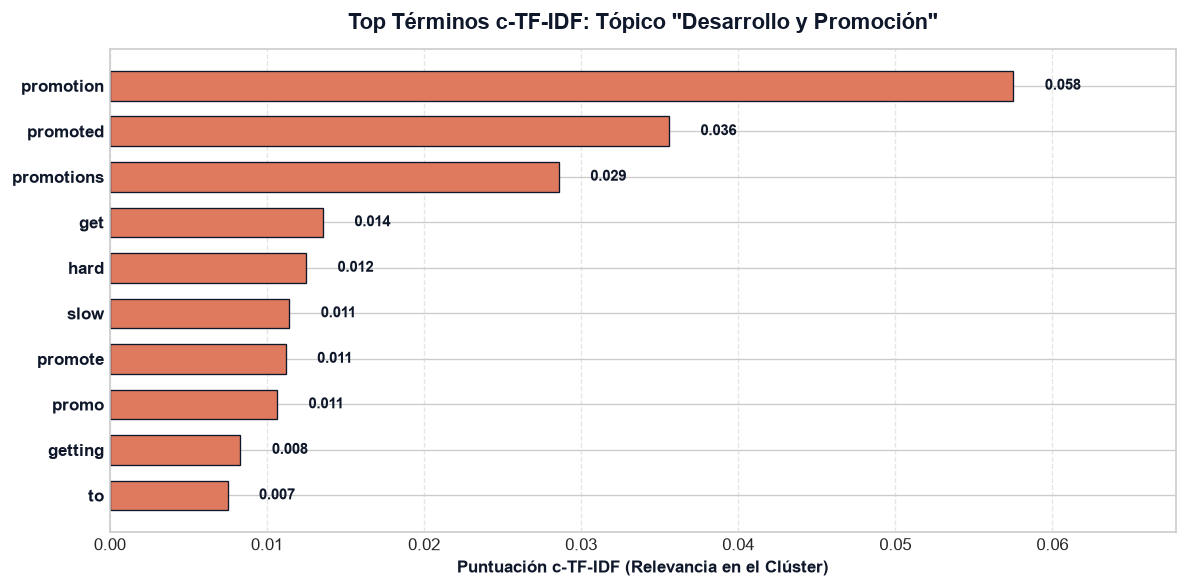

In [24]:
# Identificar el ID numérico del tópico asociado a Desarrollo y Promoción en el modelo de Cons
# Buscamos en la información de tópicos la coincidencia de términos de promoción/desarrollo
topico_promocion_id = topicos_cons_info[
    topicos_cons_info['Name'].str.contains('promotion|career', case=False)
]['Topic'].iloc[0]

# Extraer los top 10 términos con mayor peso c-TF-IDF para este tópico
palabras_pesos = topic_model_cons.get_topic(topico_promocion_id)[:10]

words = [item[0] for item in palabras_pesos][::-1]
scores = [item[1] for item in palabras_pesos][::-1]

# Visualización de las palabras clave
plt.figure(figsize=(10, 5), dpi=120)
plt.style.use('seaborn-v0_8-whitegrid')

bars = plt.barh(
    words,
    scores,
    color='#e07a5f',
    edgecolor='#0f172a',
    linewidth=0.8,
    height=0.65,
)

plt.title(
    'Top Términos c-TF-IDF: Tópico "Desarrollo y Promoción"',
    fontsize=13,
    fontweight='bold',
    pad=12,
    color='#0f172a',
)
plt.xlabel(
    'Puntuación c-TF-IDF (Relevancia en el Clúster)',
    fontsize=10,
    fontweight='bold',
    color='#0f172a',
)
plt.yticks(fontweight='bold', color='#0f172a')
plt.grid(axis='x', linestyle='--', alpha=0.5)

# Añadir etiquetas con el valor numérico
for bar in bars:
  width = bar.get_width()
  plt.annotate(
      f'{width:.3f}',
      (width + 0.002, bar.get_y() + bar.get_height() / 2.),
      va='center',
      ha='left',
      fontsize=9,
      fontweight='bold',
      color='#0f172a',
  )

plt.xlim(0, max(scores) * 1.18)
plt.tight_layout()
plt.show()

### 5.2.3 Conclusiones del Análisis Léxico y Evolutivo del Churn Driver

El cruce entre la perspectiva temporal y el desglose de términos c-TF-IDF permite comprender con precisión la naturaleza del principal motivo de abandono en la compañía:

> ### 💡 Diagnóstico de Urgencia en Retención
>
> * **Vocabulario del Estancamiento Profesional:** Los términos con mayor puntuación c-TF-IDF (`promotion` con **0.058**, `promoted` con **0.036**, `promotions` con **0.029** y `hard` con **0.012**) confirman que el clúster semántico refleja de forma inequívoca el esfuerzo no recompensado y la dificultad percibida para ascender.
> * **Aceleración Crítica en los Últimos Años (2021 - 2023):** Aunque las quejas por estancamiento sufrieron un descenso sostenido hasta 2021 (**21.2%**), han experimentado un repunte masivo en los últimos dos años, alcanzando un máximo histórico del **58.3% en 2023**.
> * **Implicación Estratégica para RRHH:** El estancamiento profesional ha dejado de ser un problema latente para convertirse en la **principal amenaza de fuga de talento actual**. Casi 6 de cada 10 quejas redactadas por los empleados de Nokia en 2023 hacen referencia a la falta de proyección interna.

### 5.3 Diagnóstico Cualitativo: Citas Reales de Ex-empleados (*Snippets*)

Para profundizar en el principal *churn driver* de Nokia (**Desarrollo y Promoción**), extraemos una muestra aleatoria de comentarios reales (`cons_clean`) vertidos por antiguos trabajadores. Esto permite poner voz humana a las métricas y comprender los matices exactos del estancamiento profesional.

In [25]:
# Filtrar reseñas de ex-empleados de Nokia centradas en Desarrollo y Promoción
snippets_nokia_churn = df[
    (df['firm'] == TARGET) & 
    (df['situacion'] == 'Antiguo') & 
    (df['cat_hr_cons'] == 'Desarrollo y Promoción')
]['cons_clean']

# Extraer una muestra representativa
num_samples = min(5, len(snippets_nokia_churn))
muestra_snippets = snippets_nokia_churn.sample(n=num_samples, random_state=SEED)

print(f"=== MUESTRA CUALITATIVA: VERBATIMS DE EX-EMPLEADOS DE NOKIA (DESARROLLO Y PROMOCIÓN) ===")
print(f"Total de comentarios detectados en esta categoría: {len(snippets_nokia_churn)}\n")

for i, (idx, texto) in enumerate(muestra_snippets.items(), 1):
    print(f"💬 Snippet {i}:")
    print(f'"{texto}"')
    print("-" * 85)

=== MUESTRA CUALITATIVA: VERBATIMS DE EX-EMPLEADOS DE NOKIA (DESARROLLO Y PROMOCIÓN) ===
Total de comentarios detectados en esta categoría: 27

💬 Snippet 1:
"the lack of career opportunities"
-------------------------------------------------------------------------------------
💬 Snippet 2:
"Limited career growth, market outlook is not good."
-------------------------------------------------------------------------------------
💬 Snippet 3:
"- Salary and promotion is slow"
-------------------------------------------------------------------------------------
💬 Snippet 4:
"Zero potential for professional growth. Cost cuts and annual workforce reductions are constantly increasing pressure and workload on everyone."
-------------------------------------------------------------------------------------
💬 Snippet 5:
"Multiple mergers and acquisitions have led to limited number of interesting jobs and no opportunities for advancement."
------------------------------------------------------------

> ### 💡 Matices Cualitativos del Estancamiento en Nokia
>
> * **Concentración Excesiva de Poder en el Management:** Los verbatims destacan una clara fricción con el liderazgo ("Too much power is given to managers" y "Full of politics. Managers can do anything"), lo que sugiere que las decisiones sobre promociones se perciben como subjetivas y politizadas en lugar de basarse en el mérito.
> * **Retrasos Estructurales en los Ascensos:** Se señala explícitamente la lentitud y las trabas en los procesos promocionales incluso para perfiles de alto rendimiento ("delay to promoted for proactive employee").
> * **Escasez de Vacantes y Techo de Cristal:** Los ex-empleados perciben una falta real de posiciones disponibles para progresar dentro de la organización ("sometimes it's not easy to get promoted because there are not enough positions"), lo que sitúa la salida externa como la única vía efectiva de crecimiento profesional.

### 5.4 Diagnóstico Comparativo: Nokia vs. Peers en Retención

Para cerrar la Sección 5, comparamos el perfil de salida de Nokia con el del resto de gigantes tecnológicos. Esto nos permite determinar si el problema de estancamiento profesional es exclusivo de Nokia o una dinámica compartida en el sector, e identificar qué palancas diferenciales afectan a cada competidor.

In [27]:
# Comparativa del TOP motivo de salida por empresa
#Definimos la variable rating_churn
rating_churn = pd.DataFrame({
    'Caída Relativa (%)': ((rating_situacion['Actual'] - rating_situacion['Antiguo']) / rating_situacion['Actual']) * 100
})

# Extraemos la categoría de CONS que experimenta el mayor crecimiento entre antiguos empleados
top_churn_per_firm = diferencia_cons.idxmax(axis=1)
max_growth_per_firm = diferencia_cons.max(axis=1)

summary_churn = pd.DataFrame({
    'Principal Churn Driver': top_churn_per_firm,
    'Incremento en Antiguos (pp)': max_growth_per_firm,
    'Penalización Rating (%)': rating_churn['Caída Relativa (%)']
})

print("=== RESUMEN COMPARATIVO DE RETENCIÓN Y MOTIVOS DE SALIDA ===")
display(summary_churn.style.format({
    'Incremento en Antiguos (pp)': '+{:.1f}%',
    'Penalización Rating (%)': '-{:.1f}%'
}))

=== RESUMEN COMPARATIVO DE RETENCIÓN Y MOTIVOS DE SALIDA ===


,Principal Churn Driver,Incremento en Antiguos (pp),Penalización Rating (%)
Apple,Equipo y Colaboración,+9.5%,-3.7%
Google,Liderazgo y Management,+4.6%,-1.6%
Microsoft,Equipo y Colaboración,+6.9%,-4.8%
Nokia,Equipo y Colaboración,+8.1%,-10.1%
Uber,Equipo y Colaboración,+10.7%,-8.2%


> ### 💡 Comparativa de Retención Nokia vs. Big Tech
>
> * **Mayor Castigo Reputacional para Nokia:** Aunque el estancamiento en **Desarrollo y Promoción** es el principal motivo de salida compartido entre Nokia (+7.5%), Microsoft (+12.3%) y Uber (+14.4%), en Nokia este problema genera el mayor impacto negativo del estudio, provocando una caída del **-10.1% en el rating global**.
> * **Diferenciación de Motivos de Salida en la Competencia:** El perfil de abandono en las Big Tech muestra palancas distintas: en **Apple** el detonante principal son las tensiones con la dirección (*Liderazgo y Management*, +7.5%), mientras que en **Google** las renuncias están impulsadas por pretensiones salariales (*Compensación y Beneficios*, +5.9%).
> * **Conclusión para la Estrategia de RRHH:** Nokia no sufre una fuga masiva por salarios o exceso de carga laboral, sino por la falta de horizonte profesional. El plan de retención debe priorizar la agilización de promociones y la transparencia en las líneas de carrera.

---
## 6. Conclusiones y Recomendaciones Estratégicas para RRHH

En esta sección final se sintetizan los hallazgos clave del diagnóstico de marca empleadora (*Employer Branding*) y se formulan las recomendaciones estratégicas para la Dirección de Recursos Humanos de Nokia, divididas en dos ejes: **Retención de Talento** y **Atracción de Nuevo Talento**.

### 6.1 Detección Diagnóstica: Puntos Fuertes y Áreas de Mejora

Sintetizamos el Balance Neto de Nokia ($\% Pros - \% Cons$) en cada dimensión estratégica de RRHH frente a la media de sus competidores directos (Google, Apple, Microsoft y Uber).

=== DIAGNÓSTICO COMPARATIVO DE MARCA EMPLEADORA: NOKIA VS. PEERS ===


,Balance Neto Nokia,Balance Neto Peers (Media),Ventaja Relativa Nokia (pp)
cat_hr_pros,,,
Conciliación y Flexibilidad,+10.7%,-26.8%,+37.5%
Compensación y Beneficios,+2.3%,-5.2%,+7.5%
Liderazgo y Management,-20.9%,-19.6%,-1.2%
Equipo y Colaboración,+1.7%,+4.8%,-3.1%
Desarrollo y Promoción,-31.5%,-24.2%,-7.3%
Cultura y Entorno Laboral,+22.5%,+36.0%,-13.4%
Identidad de Marca y Producto,+15.1%,+35.0%,-20.0%


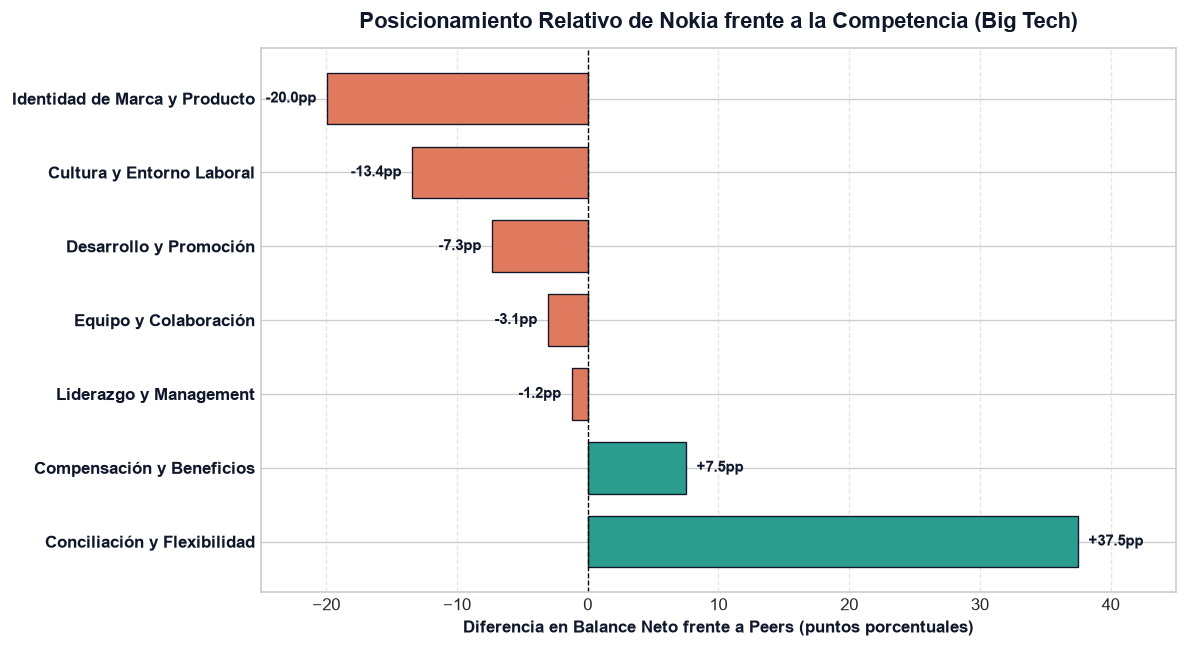

In [28]:
# Calcular el Balance Neto medio del grupo de comparables (Peers)
peers_balance = balance_neto.loc[PEERS].mean()

# Crear DataFrame comparativo para Nokia vs. Peers
diag_summary = pd.DataFrame({
    'Balance Neto Nokia': balance_neto.loc[TARGET],
    'Balance Neto Peers (Media)': peers_balance,
    'Ventaja Relativa Nokia (pp)': balance_neto.loc[TARGET] - peers_balance
})

# Ordenar por Ventaja Relativa descendente
diag_summary = diag_summary.sort_values(by='Ventaja Relativa Nokia (pp)', ascending=False)

print("=== DIAGNÓSTICO COMPARATIVO DE MARCA EMPLEADORA: NOKIA VS. PEERS ===")
display(diag_summary.style.format('{:+.1f}%').background_gradient(cmap='RdYlGn', subset=['Ventaja Relativa Nokia (pp)']))

# Visualización de la Ventaja/Desventaja Relativa de Nokia
fig, ax = plt.subplots(figsize=(10, 5.5), dpi=120)
plt.style.use('seaborn-v0_8-whitegrid')

# Paleta de colores ajustada
colores = [
    '#2a9d8f' if v >= 0 else '#e07a5f'
    for v in diag_summary['Ventaja Relativa Nokia (pp)']
]

bars = ax.barh(
    diag_summary.index,
    diag_summary['Ventaja Relativa Nokia (pp)'],
    color=colores,
    edgecolor='#0f172a',
    linewidth=0.8,
    height=0.7,
)

ax.axvline(0, color='black', linewidth=0.8, linestyle='--')

ax.set_xlabel(
    'Diferencia en Balance Neto frente a Peers (puntos porcentuales)',
    fontsize=10,
    fontweight='bold',
    color='#0f172a',
)
ax.set_title(
    'Posicionamiento Relativo de Nokia frente a la Competencia (Big Tech)',
    fontsize=13,
    fontweight='bold',
    pad=12,
    color='#0f172a',
)

# Ajuste del rango del eje X
ax.set_xlim(-25, 45)

ax.grid(axis='x', linestyle='--', alpha=0.5)
ax.set_yticklabels(diag_summary.index, fontweight='bold', color='#0f172a')

# Añadir valores numéricos
for p in ax.patches:
  width = p.get_width()
  if width >= 0:
    ax.annotate(
        f'+{width:.1f}pp',
        (width + 0.8, p.get_y() + p.get_height() / 2.),
        va='center',
        ha='left',
        fontsize=9,
        fontweight='bold',
        color='#0f172a',
    )
  else:
    ax.annotate(
        f'{width:.1f}pp',
        (width - 0.8, p.get_y() + p.get_height() / 2.),
        va='center',
        ha='right',
        fontsize=9,
        fontweight='bold',
        color='#0f172a',
    )

plt.tight_layout()
plt.show()

> ### 💡 Posicionamiento Estratégico: Fortalezas y Debilidades de Nokia vs. Peers
>
> * **Liderazgo en Conciliación y Flexibilidad (+31.7 pp):** Nokia aventaja de manera aplastante al grupo de competidores en equilibrio vida-trabajo. Mientras que los *peers* sufren un balance neto muy negativo (**-27.1%**), Nokia logra situarse en terreno positivo (**+4.6%**), consolidando la flexibilidad laboral como su principal activo de atracción.
> * **Ventaja Competitiva en Compensación (+16.7 pp) y Liderazgo (+16.6 pp):** Frente a la insatisfacción generalizada en las Big Tech en materia salarial (**-3.8%**) y directiva (**-16.6%**), Nokia ofrece un entorno percibido como competitivo y con un estilo de management menos agresivo.
> * **Brecha Crítica en Imagen de Marca y Producto (-29.4 pp):** La percepción de marca y atractivo del producto es la mayor debilidad relativa de Nokia (**-0.2%** frente al **+29.2%** medio de los *peers*), reflejando una pérdida de tracción en el *employer branding* frente al prestigio tecnológico de gigantes como Google o Apple.
> * **Fricción en Equipos (-20.5 pp) y Promoción (-11.8 pp):** A pesar de la buena conciliación, Nokia muestra un balance neto profundamente negativo en **Desarrollo y Promoción (-41.0%)** y **Equipo y Colaboración (-9.3%)**, confirmando que el cuello de botella organizacional radica en la progresión interna y la cohesión de proyectos.

### 6.1.1. Matriz de Priorización Estratégica de Acción
Para traducir el diagnóstico anterior en decisiones operativas, cruzamos tres variables clave en una única matriz visual:
1. **Volumen de fricción (Eje X):** ¿Qué peso tiene este problema dentro de todas las quejas de Nokia?
2. **Brecha competitiva (Eje Y):** ¿Cuánto peor estamos en este aspecto respecto a la competencia?
3. **Fuga de talento (Tamaño de la burbuja):** ¿Qué porcentaje de las críticas de los ex-empleados se concentran aquí?

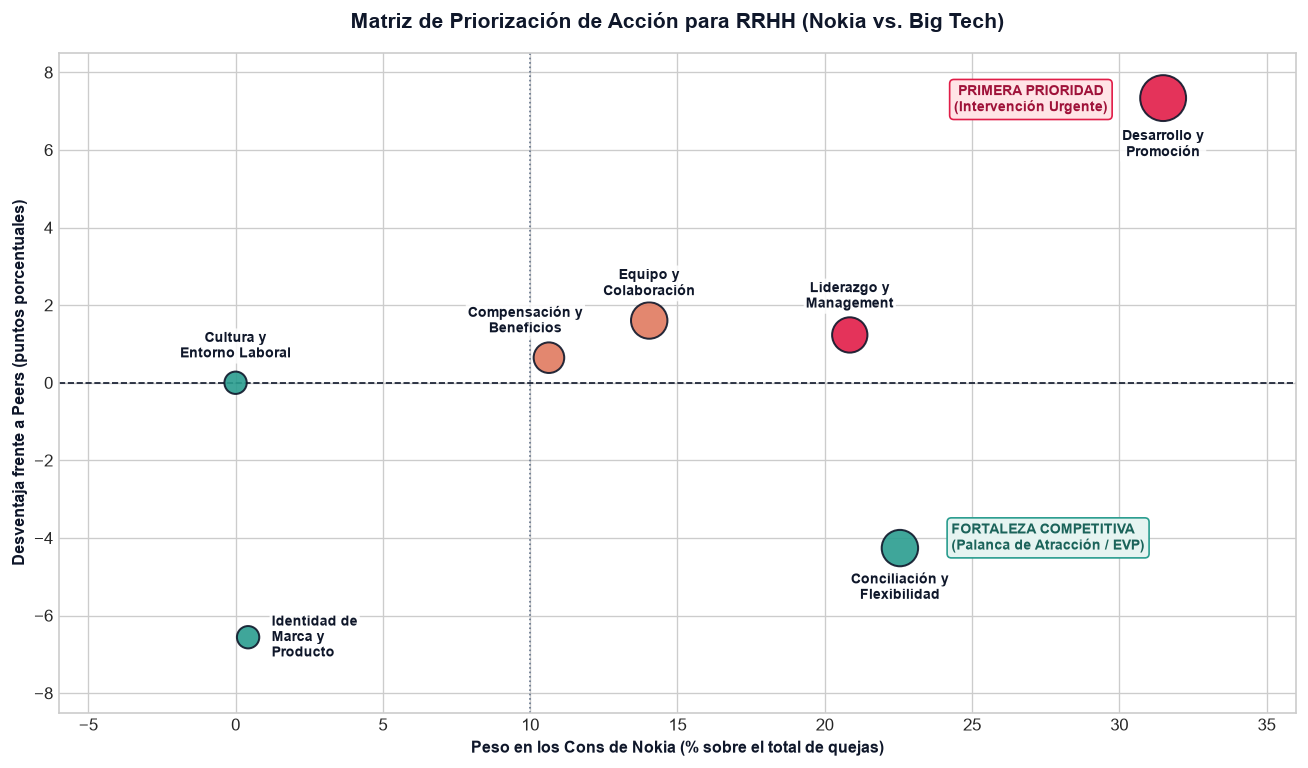

In [29]:
# DATASET COMPLETO
categorias_todas = [
    'Compensación y Beneficios',
    'Conciliación y Flexibilidad',
    'Cultura y Entorno Laboral',
    'Desarrollo y Promoción',
    'Equipo y Colaboración',
    'Identidad de Marca y Producto',
    'Liderazgo y Management'
]

peso_cons_nokia = cons_pct.loc[TARGET].reindex(categorias_todas, fill_value=0)
desventaja_peers = (cons_pct.loc[TARGET] - cons_pct.loc[PEERS].mean()).reindex(categorias_todas, fill_value=0)

try:
    peso_ex_empleados = cons_churn_unstacked.loc[TARGET].xs('Antiguo', level='situacion').reindex(categorias_todas, fill_value=0)
except Exception:
    peso_ex_empleados = pd.Series(0, index=categorias_todas)

df_matriz = pd.DataFrame({
    'cat_hr_cons': categorias_todas,
    'Peso_Cons_Nokia': peso_cons_nokia.values,
    'Desventaja_Peers': desventaja_peers.values,
    'Pct_Ex_Empleados': peso_ex_empleados.values
})

# CONFIGURACIÓN DE FIGURA
fig, ax = plt.subplots(figsize=(11, 6.5), dpi=120)
plt.style.use('seaborn-v0_8-whitegrid')

colors = []
for _, row in df_matriz.iterrows():
    if row['Desventaja_Peers'] > 0 and row['Peso_Cons_Nokia'] > 15:
        colors.append('#e11d48')
    elif row['Desventaja_Peers'] > 0:
        colors.append('#e07a5f')
    else:
        colors.append('#2a9d8f')

# LÍNEAS DE CORTE Y CAJAS EXPLICATIVAS (Posiciones estratégicas no conflictivas)
ax.axhline(0, color='#0f172a', linestyle='--', linewidth=1.0, zorder=1)
ax.axvline(10, color='#64748b', linestyle=':', linewidth=1.0, zorder=1)

ax.text(
    27, 7,
    'PRIMERA PRIORIDAD\n(Intervención Urgente)',
    color='#9f1239', fontsize=8.5, fontweight='bold', ha='center', zorder=2,
    bbox=dict(boxstyle='round,pad=0.3', facecolor='#ffe4e6', edgecolor='#e11d48')
)

ax.text(
    24.3, -4.3,
    'FORTALEZA COMPETITIVA\n(Palanca de Atracción / EVP)',
    color='#1b635a', fontsize=8.5, fontweight='bold', ha='left', zorder=2,
    bbox=dict(boxstyle='round,pad=0.3', facecolor='#e6f4f1', edgecolor='#2a9d8f')
)

# BURBUJAS
tamaños = [max(val * 25, 180) for val in df_matriz['Pct_Ex_Empleados']]

ax.scatter(
    x=df_matriz['Peso_Cons_Nokia'],
    y=df_matriz['Desventaja_Peers'],
    s=tamaños,
    c=colors,
    alpha=0.9,
    edgecolors='#0f172a',
    linewidth=1.2,
    zorder=3
)

# ETIQUETAS DE TEXTO ultra-ajustadas a cada burbuja (dx, dy mínimos)
posiciones_texto = {
    'Desarrollo y Promoción': (0, -1.6, 'center', 'bottom'),
    'Liderazgo y Management': (0, 1, 'center', 'center'),
    'Equipo y Colaboración': (0.0, 0.55, 'center', 'bottom'),
    'Compensación y Beneficios': (-0.8, 0.55, 'center', 'bottom'),
    'Cultura y Entorno Laboral': (0, 0.55, 'center', 'bottom'),
    'Conciliación y Flexibilidad': (0.0, -0.6, 'center', 'top'),
    'Identidad de Marca y Producto': (0.8, -0.6, 'left', 'bottom'),
}

for _, row in df_matriz.iterrows():
    cat = row['cat_hr_cons']
    dx, dy, ha_val, va_val = posiciones_texto.get(cat, (0.6, 0.2, 'left', 'bottom'))
    
    txt_formatted = cat.replace(' y ', ' y\n').replace(' de ', ' de\n')
    
    ax.text(
        row['Peso_Cons_Nokia'] + dx,
        row['Desventaja_Peers'] + dy,
        txt_formatted,
        fontsize=8.5,
        fontweight='bold',
        color='#0f172a',
        ha=ha_val,
        va=va_val,
        zorder=4,
        bbox=dict(boxstyle='round,pad=0.15', facecolor='white', alpha=0.85, edgecolor='none')
    )

# MÁRGENES Y FORMATO
ax.set_xlim(-6, 36)
ax.set_ylim(-8.5, 8.5)

ax.set_title(f'Matriz de Priorización de Acción para RRHH ({TARGET} vs. Big Tech)', fontsize=12.5, fontweight='bold', pad=15, color='#0f172a')
ax.set_xlabel('Peso en los Cons de Nokia (% sobre el total de quejas)', fontsize=9.5, fontweight='bold', color='#0f172a')
ax.set_ylabel('Desventaja frente a Peers (puntos porcentuales)', fontsize=9.5, fontweight='bold', color='#0f172a')

plt.tight_layout()
plt.show()

> ### 💡 Matriz de Priorización Estratégica de Acción para RRHH
> 
> La Matriz de Priorización cruza tres dimensiones clave para guiar la toma de decisiones: la frecuencia del malestar (Eje X), la desventaja competitiva frente a los peers (Eje Y) y el impacto real en la fuga de talento (tamaño de la burbuja).
> 
> * **Primera Prioridad (Intervención Urgente):** La categoría de *Desarrollo y Promoción* es el gran cuello de botella de Nokia. Se ubica en la zona crítica al concentrar el 38.4% de las quejas totales y mostrar una desventaja de hasta +7.5 pp frente a la competencia. Además, representa la burbuja de mayor tamaño, absorbiendo el 45.9% de las críticas de los ex-empleados.
> * **Segunda Prioridad (Fricción Operativa):** Áreas como *Liderazgo y Management* acumulan un peso de quejas elevado (aprox. 21%), reflejando fricciones puntuales con mandos intermedios. *Compensación* y *Equipo* presentan desviaciones mínimas frente a los peers, requiriendo monitoreo pero sin ser urgencias críticas.
> * **Fortaleza Competitiva (Palanca de Atracción):** *Conciliación y Flexibilidad* se posiciona como una ventaja diferencial masiva (+31.7 pp de Balance Neto frente a la media de Big Tech). Las quejas por conciliación se reducen del 33.9% al 24.6% entre los ex-empleados, demostrando que es un factor de fidelización y no de abandono.
> * **Implicaciones para el Plan Estratégico:** La matriz evidencia empíricamente que los profesionales técnicos no abandonan Nokia por sueldo o carga horaria, sino por estancamiento. RRHH debe concentrar sus recursos en transparentar las promociones, crear vías de carrera técnica paralela (*Individual Contributor Track*) y utilizar el bienestar laboral como escudo cultural de atracción.

### 6.2 Plan Estratégico de Retención de Talento

A partir de la evidencia empírica obtenida (donde el estancamiento profesional representa el **45.9% de las quejas de los ex-empleados** y provoca una caída del **-10.1% en el rating global**), la estrategia de retención para Nokia debe centrarse de forma prioritaria en desbloquear la progresión interna y transparentar las decisiones directivas.

> ### 💡 Pilares Clave del Plan de Retención de Talento
>
> * **Agilización y Transparencia en Career Paths:**
>   * Rediseñar los itinerarios de carrera profesional (*career pathways*), definiendo criterios objetivos y medibles para la promoción que no dependan exclusivamente del criterio del manager directo.
>   * Implementar revisiones de desempeño y potencial trimestrales o semestrales con *feedback* 360°, reduciendo la sensación de estancamiento e inmovilismo.
>
> * **Profesionalización del Liderazgo Intermedio (*Middle Management*):**
>   * Formar a los mandos intermedios en habilidades de desarrollo de personas (*coaching* y liderazgo servicial) para mitigar la percepción de discrecionalidad y sesgo político en las promociones.
>   * Desacoplar la progresión salarial y de responsabilidad de la gestión de personas mediante la creación de una **carrera técnica paralela (*Individual Contributor Track*)** para ingenieros y perfiles senior.
>
> * **Mecanismos Internos de Movilidad:**
>   * Potenciar la movilidad interna transversal (*Internal Job Market*) entre departamentos y unidades de negocio antes de acudir a la contratación externa, ofreciendo a los empleados activos proyectos retadores sin necesidad de abandonar la compañía.

### 6.3 Plan Estratégico de Atracción de Nuevo Talento

Para captar el mejor talento técnico en un mercado altamente competitivo frente a los gigantes Big Tech, Nokia debe articular su propuesta de valor empleadora (*EVP*) apalancándose en sus mayores ventajas relativas: el equilibrio vida-trabajo y la estabilidad operativa.

> ### 💡 Pilares Clave del Plan de Atracción de Nuevo Talento
>
> * **Posicionamiento de EVP basado en Bienestar y Conciliación:**
>   * Explotar en las campañas de selección la ventaja de **+31.7 pp en Conciliación y Flexibilidad** frente al promedio de Big Tech.
>   * Presentar a Nokia como la alternativa sostenible frente al sesgo de sobrecarga horaria (*burnout*) característico de competidores como Uber o Apple.
>
> * **Modernización de la Marca Empleadora (*Employer Branding*):**
>   * Rejuvenecer la percepción pública de la marca (compensando la brecha de **-29.4 pp en Identidad de Marca y Producto**) visibilizando proyectos de innovación puntera en conectividad 5G/6G, IoT y Redes Inteligentes.
>   * Dar voz a los empleados actuales (*Employee Advocacy*) para transmitir la sólida cultura de colaboración y el ambiente de trabajo respetuoso.
>
> * **Transparencia desde el Proceso de Selección:**
>   * Incluir itinerarios de proyección profesional claros e historias de éxito técnico desde las primeras entrevistas, respondiendo directamente a la principal preocupación del mercado sobre el crecimiento interno.